# 07 — Model Evaluation and Generalization in Biological Data

### How to measure what a model will really do on new patients — and how not to fool yourself

**Learning path:** `Deep Learning / Keras`  
**Notebook:** 07 of 12  
**Level:** Intermediate → advanced  
**Primary tools:** Python, NumPy, pandas, Matplotlib, Keras 3  
**Dataset:** UCI *Gene expression cancer RNA-Seq* (801 tumours, 20,531 genes, 5 cancer types; introduced in Notebook 06)

---

## Learning objectives

By the end of this notebook, you should be able to:

1. State precisely **what an evaluation estimates**, and attach honest confidence intervals (Wilson and Clopper–Pearson) to an accuracy, a sensitivity, or a recall computed on a small test set.
2. Explain why **stratified** splitting matters, and quantify the variability of class counts in random splits.
3. Define **data leakage**, classify its forms, and **prove and simulate** why selecting features on the whole dataset inflates performance when $p \gg n$ (the expected maximum of $p$ null statistics grows like $\sqrt{2\ln p}$).
4. Compute sensitivity, specificity, PPV, NPV, F1/F$_\beta$, balanced accuracy, and MCC from scratch, and use **Bayes' theorem** to explain why a good test can still have a poor positive predictive value for a rare condition.
5. Define the **ROC curve** and **AUC**, prove that AUC equals the probability that a random positive outscores a random negative, build **precision–recall curves**, and explain why PR curves are more informative under class imbalance.
6. Choose a **decision threshold** from validation data and from misclassification costs (derive $p^* = c_{FP}/(c_{FP}+c_{FN})$), and assess **calibration** (reliability diagram, Brier score, ECE).
7. Use **cross-validation, repeated cross-validation, and nested cross-validation**; explain the "winner's curse" of selecting the best of many models.
8. Compare models with **paired** procedures: McNemar's test, the corrected resampled $t$-test, and a permutation test.
9. Write an honest, reproducible **evaluation report**.

> **How is this notebook different?** Most earlier notebooks trained models. This one is about *measurement*. Because the dataset has 801 patients, we can run a rare kind of experiment: we repeatedly draw small "pilot cohorts", measure performance in several ways, and compare each estimate with the performance on all remaining patients, which plays the role of the unseen future. That lets us **measure the quality of evaluation methods themselves**.

## 1. What does an evaluation estimate?

A trained model $f$ has a **true performance** on the population it will be used for. For the 0–1 loss this is the true accuracy

$$
A(f) = \mathbb{P}\big(f(X) = Y\big),
$$

the probability of a correct prediction on a *new* patient drawn from the target population. A test set $\{(x_i, y_i)\}_{i=1}^{n}$ gives the **estimator**

$$
\hat{A} = \frac{1}{n}\sum_{i=1}^{n}\mathbf{1}\{f(x_i)=y_i\} .
$$

If the test patients are an independent sample from the population and were **not** used to build the model, then $n\hat{A} \sim \operatorname{Binomial}(n, A)$, so

$$
\mathbb{E}[\hat{A}] = A \quad(\text{unbiased}), \qquad \operatorname{Var}(\hat{A}) = \frac{A(1-A)}{n} .
$$

Three things can go wrong, and they correspond to the three parts of this notebook:

| Failure | Meaning | Remedy |
|---|---|---|
| **Optimistic bias** | the estimator's mean is above the truth (leakage, selection on the test set, winner's curse) | strict separation of data used for decisions and data used for reporting; nested procedures |
| **High variance** | the estimate is correct on average but, with few test samples, it can be far off | confidence intervals, repeated or cross-validated estimates, paired comparisons |
| **Distribution shift** | the test patients are not like the future patients (other hospital, other platform, other population) | external validation, honest statements of scope |

The first two can be studied by simulation and are the focus here; the third can only be addressed by data and design, and we will discuss it in the final section.

## 2. Set up the environment

We use Keras 3 with the TensorFlow backend, but **most of this notebook is NumPy**: evaluation methodology is easier to understand (and to verify) when every formula is written out. Keras is used only for the neural-network models of Sections 15–16. Select the backend before importing Keras.

**Runtime.** The repeated-cohort experiments run hundreds of small fits in NumPy and take a few minutes. Set `QUICK_MODE = True` to use fewer replicates (about 3× faster) for a first read.

In [2]:
# If needed, install the packages in the active Jupyter environment:
# %pip install -U keras tensorflow numpy pandas matplotlib

In [3]:
# Select the backend BEFORE importing Keras.
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import sys, json, math, time, tarfile, urllib.request
from math import comb, lgamma

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import keras

SEED = 42
keras.utils.set_random_seed(SEED)

QUICK_MODE = False                      # True: fewer replicates and permutations
REPLICATES = 30 if QUICK_MODE else 100  # number of simulated pilot cohorts per cohort size
N_PERMUTATIONS = 60 if QUICK_MODE else 200
N_BOOT = 500 if QUICK_MODE else 2000

ARTIFACT_DIR = "artifacts_07"
FIG_DIR = "figures_07"
for folder in (ARTIFACT_DIR, FIG_DIR):
    os.makedirs(folder, exist_ok=True)

print("Python :", sys.version.split()[0])
print("Keras  :", keras.__version__, "| backend:", keras.backend.backend())
print("NumPy  :", np.__version__, "| pandas:", pd.__version__)
print("Replicates per cohort size:", REPLICATES, "| permutations:", N_PERMUTATIONS, "| bootstrap resamples:", N_BOOT)

Python : 3.11.0
Keras  : 3.15.1 | backend: tensorflow
NumPy  : 2.4.6 | pandas: 2.3.3
Replicates per cohort size: 100 | permutations: 200 | bootstrap resamples: 2000


## 3. Visual style

The same style as before. Here, three *evaluation protocols* get fixed colours that are used consistently in all comparisons: **correct** procedures are blue/green, **leaky** (flawed) procedures are red.

In [4]:
COLORS = {"blue": "#2563EB", "orange": "#F59E0B", "green": "#10B981", "red": "#EF4444",
          "purple": "#8B5CF6", "gray": "#6B7280", "dark": "#111827", "light": "#E5E7EB",
          "teal": "#0D9488", "pink": "#DB2777"}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": COLORS["gray"], "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["light"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.labelcolor": COLORS["dark"], "xtick.color": COLORS["dark"], "ytick.color": COLORS["dark"],
    "font.size": 10, "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2.0,
})

SAVE_FIGURES = True
def finish(fig, name, pad=1.0):
    fig.tight_layout(pad=pad)
    if SAVE_FIGURES:
        fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Part I — The mathematics of evaluation (with simulations)

## 4. How uncertain is an accuracy computed on $n$ samples?

Since $n\hat{A} \sim \operatorname{Binomial}(n, A)$, we can build confidence intervals for $A$. Let $k$ be the number of correct predictions, $\hat{p} = k/n$, and $z = 1.96$ for 95%.

| Interval | Formula | Comment |
|---|---|---|
| **Wald** | $\hat{p} \pm z\sqrt{\hat{p}(1-\hat{p})/n}$ | the textbook formula; **unreliable** near 0 or 1 and for small $n$ (can leave $[0,1]$, width 0 when $\hat{p}=1$) |
| **Wilson** | $\dfrac{\hat{p} + \frac{z^2}{2n} \pm z\sqrt{\frac{\hat{p}(1-\hat{p})}{n} + \frac{z^2}{4n^2}}}{1 + z^2/n}$ | inverts the score test; good coverage even for small $n$ |
| **Clopper–Pearson** | the $p$ for which $\mathbb{P}(X \ge k \mid p) = \alpha/2$ (lower) and $\mathbb{P}(X \le k \mid p) = \alpha/2$ (upper) | "exact", guaranteed coverage $\ge 1-\alpha$, conservative |

These intervals apply to any proportion in an evaluation: accuracy, sensitivity (successes among the *positive* patients, so $n$ is the number of positives!), or specificity.

**The consequence for rare classes.** The relevant $n$ for the recall of a class is the number of patients *in that class*. With 78 COAD tumours in total, a test set of 160 patients contains about 16 of them: a recall of "15/16 = 94%" has a 95% Wilson interval of roughly 72–99%.

In [5]:
def wilson_interval(k, n, z=1.959964):
    if n == 0:
        return 0.0, 1.0
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return max(0.0, centre - half), min(1.0, centre + half)

def wald_interval(k, n, z=1.959964):
    p = k / n
    half = z * math.sqrt(p * (1 - p) / n)
    return p - half, p + half

def binom_cdf(k, n, p):
    """P(X <= k) for X ~ Binomial(n, p), computed with log-probabilities."""
    if k < 0: return 0.0
    if k >= n: return 1.0
    if p <= 0: return 1.0
    if p >= 1: return 0.0
    total = 0.0
    for i in range(k + 1):
        total += math.exp(lgamma(n + 1) - lgamma(i + 1) - lgamma(n - i + 1) + i * math.log(p) + (n - i) * math.log(1 - p))
    return min(1.0, total)

def clopper_pearson(k, n, alpha=0.05):
    """Exact interval by bisection on the binomial tail probabilities."""
    def bisect(f, lo=0.0, hi=1.0, iters=60):
        for _ in range(iters):
            mid = (lo + hi) / 2
            lo, hi = (mid, hi) if f(mid) else (lo, mid)
        return (lo + hi) / 2
    lower = 0.0 if k == 0 else bisect(lambda p: 1 - binom_cdf(k - 1, n, p) < alpha / 2)   # P(X >= k | p) < alpha/2  -> raise p
    upper = 1.0 if k == n else bisect(lambda p: binom_cdf(k, n, p) > alpha / 2)           # P(X <= k | p) > alpha/2  -> raise p
    return lower, upper

print("15 successes out of 16 (e.g. recall of COAD on a test set with 16 COAD tumours):")
for name, fn in [("Wald", wald_interval), ("Wilson", wilson_interval), ("Clopper-Pearson", clopper_pearson)]:
    lo, hi = fn(15, 16)
    print(f"  {name:16s} [{lo:.3f}, {hi:.3f}]")
print("\n16 successes out of 16:")
for name, fn in [("Wald", wald_interval), ("Wilson", wilson_interval), ("Clopper-Pearson", clopper_pearson)]:
    lo, hi = fn(16, 16)
    print(f"  {name:16s} [{lo:.3f}, {hi:.3f}]   <- Wald claims certainty of 100%")

15 successes out of 16 (e.g. recall of COAD on a test set with 16 COAD tumours):
  Wald             [0.819, 1.056]
  Wilson           [0.717, 0.989]
  Clopper-Pearson  [0.698, 0.998]

16 successes out of 16:
  Wald             [1.000, 1.000]   <- Wald claims certainty of 100%
  Wilson           [0.806, 1.000]   <- Wald claims certainty of 100%
  Clopper-Pearson  [0.794, 1.000]   <- Wald claims certainty of 100%


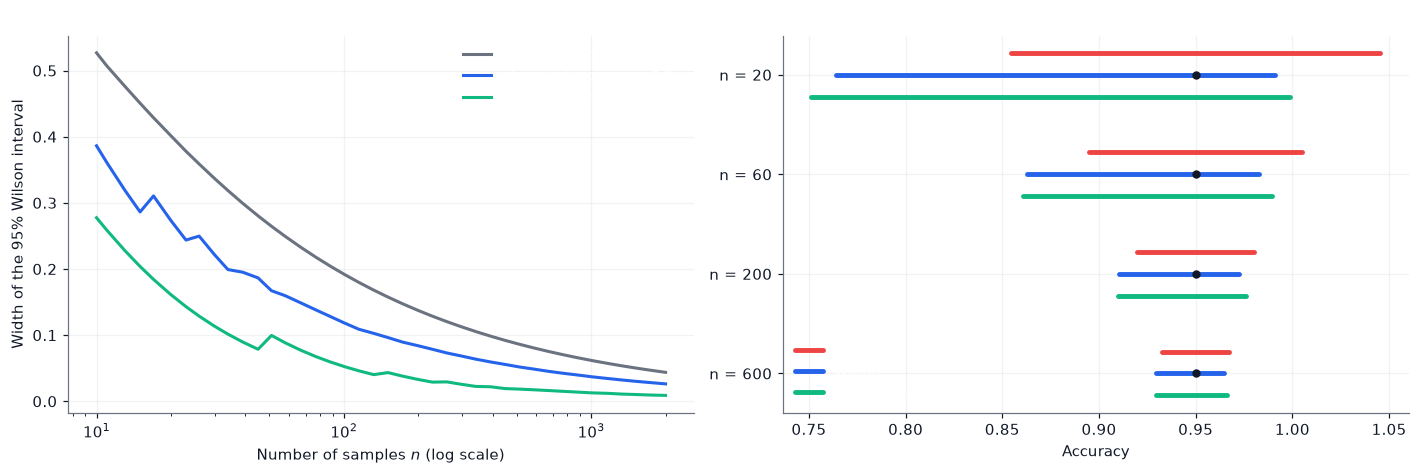

Number of test samples needed so that a 95% interval around an accuracy of 0.95 has total width about 0.05: 292


In [6]:
ns = np.unique(np.round(np.geomspace(10, 2000, 40)).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for p_true, color in [(0.5, COLORS["gray"]), (0.9, COLORS["blue"]), (0.99, COLORS["green"])]:
    widths = [np.subtract(*wilson_interval(int(round(p_true * n)), n)[::-1]) for n in ns]
    axes[0].plot(ns, widths, color=color, label=f"observed proportion {p_true}")
axes[0].set_xscale("log"); axes[0].set_xlabel("Number of samples $n$ (log scale)"); axes[0].set_ylabel("Width of the 95% Wilson interval")
axes[0].set_title("Uncertainty shrinks only like $1/\\sqrt{n}$"); axes[0].legend()

cases = [(19, 20), (57, 60), (190, 200), (570, 600)]            # all observed accuracy 0.95
for row, (k, n) in enumerate(cases):
    for offset, (name, fn, color) in zip([-0.22, 0, 0.22], [("Wald", wald_interval, COLORS["red"]),
                                                          ("Wilson", wilson_interval, COLORS["blue"]),
                                                          ("Clopper-Pearson", clopper_pearson, COLORS["green"])]):
        lo, hi = fn(k, n)
        axes[1].plot([lo, hi], [row + offset] * 2, color=color, linewidth=3.2, solid_capstyle="round", label=name if row == 0 else None)
    axes[1].scatter([k / n], [row], color=COLORS["dark"], zorder=5, s=20)
axes[1].set_yticks(range(len(cases))); axes[1].set_yticklabels([f"n = {n}" for _, n in cases]); axes[1].invert_yaxis()
axes[1].set_xlabel("Accuracy"); axes[1].set_title("Three 95% intervals for an observed accuracy of 0.95"); axes[1].legend(loc="lower left")
finish(fig, "01_confidence_intervals")
print("Number of test samples needed so that a 95% interval around an accuracy of 0.95 has total width about 0.05:",
      int(np.ceil((2 * 1.96) ** 2 * 0.95 * 0.05 / 0.05**2)))

Quadrupling the test set only halves the interval. Reporting "97.5% accuracy" for 40 test patients without an interval hides the fact that the data are compatible with anything from about 87% to 99.6%.

## 5. Splitting the data: random versus stratified

A **random** split of a dataset with a rare class can put very different numbers of that class into the test set purely by chance. If the test set contains $N_t$ samples drawn without replacement from a population of $N$ with $M$ positives, the number of positives in it is **hypergeometric**:

$$
\mathbb{E}[\#\text{pos}] = N_t\frac{M}{N}, \qquad
\operatorname{Var}[\#\text{pos}] = N_t\,\frac{M}{N}\Big(1-\frac{M}{N}\Big)\frac{N-N_t}{N-1} .
$$

A **stratified** split fixes the class proportions in every partition (up to rounding), so this variance disappears. We simulate it for COAD ($M = 78$ of $N = 801$) and a test set of 80 patients.

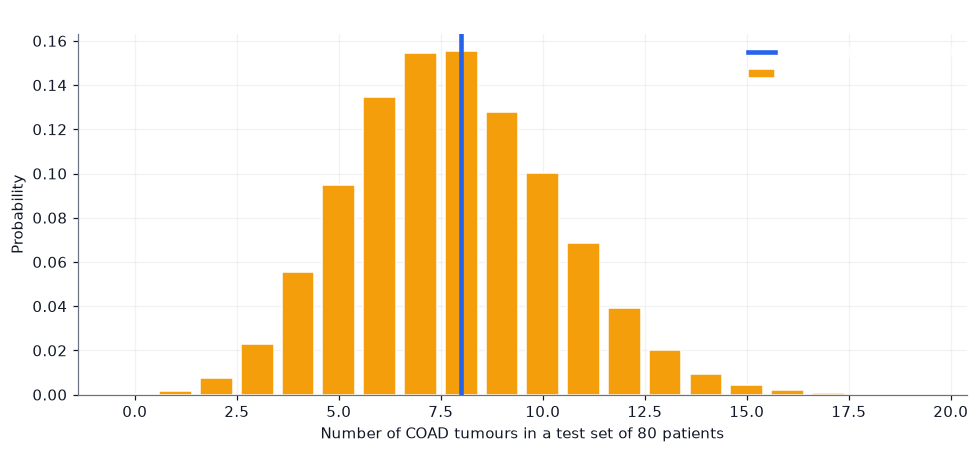

Hypergeometric mean 7.79, variance 6.34 | simulated mean 7.80, variance 6.37
Probability that a random test set has 4 or fewer COAD tumours: 0.088  (half of the expected number)


In [7]:
N_pop, M_pos, N_test = 801, 78, 80
labels_pop = np.zeros(N_pop, dtype=int); labels_pop[:M_pos] = 1
rng = np.random.default_rng(1)

random_counts = np.array([labels_pop[rng.choice(N_pop, N_test, replace=False)].sum() for _ in range(20000)])
stratified_count = int(round(N_test * M_pos / N_pop))
expected = N_test * M_pos / N_pop
variance = N_test * (M_pos / N_pop) * (1 - M_pos / N_pop) * (N_pop - N_test) / (N_pop - 1)

fig, ax = plt.subplots(figsize=(9, 4.2))
values, counts = np.unique(random_counts, return_counts=True)
ax.bar(values, counts / counts.sum(), color=COLORS["orange"], edgecolor="white", label="Random split")
ax.axvline(stratified_count, color=COLORS["blue"], linewidth=3, label=f"Stratified split: always {stratified_count}")
ax.set_xlabel("Number of COAD tumours in a test set of 80 patients"); ax.set_ylabel("Probability")
ax.set_title("Random splits give very different numbers of rare-class samples"); ax.legend()
finish(fig, "02_stratification")
print(f"Hypergeometric mean {expected:.2f}, variance {variance:.2f} | simulated mean {random_counts.mean():.2f}, variance {random_counts.var():.2f}")
print(f"Probability that a random test set has 4 or fewer COAD tumours: {np.mean(random_counts <= 4):.3f}  (half of the expected number)")

## 6. Data leakage

**Leakage** is any way in which information about the evaluation data influences the model or the choices made while building it, so that the measured performance is better than the performance on genuinely new data.

| Form | Example in biology | Fix |
|---|---|---|
| **Preprocessing fitted on all data** | standardization, imputation, PCA, batch correction computed before splitting | fit every transformation on the training partition only, inside each cross-validation fold |
| **Feature selection on all data** | choosing the "most informative genes" using *all* samples (and often their labels) | make selection part of the model, fitted inside each training fold |
| **Duplicates / related samples** | several samples from the same patient, technical replicates, close relatives, homologous proteins in different partitions | split by patient (or family, or sequence cluster): **grouped** splitting |
| **Target leakage** | a feature that is a consequence of the outcome (e.g. a treatment given *because of* the diagnosis) | domain review of every feature |
| **Test-set reuse** | trying many models and reporting the best test score | one-shot test set; nested cross-validation |
| **Batch / site confounding** | cases and controls processed on different machines; the model learns the machine | randomized design; evaluate across batches |

### 6.1 Why selecting features on all data is so dangerous when $p \gg n$

Take $p$ features that are **pure noise** (independent of the labels) and $n$ samples. The sample correlation of one noise feature with the labels is approximately $\mathcal{N}(0, 1/n)$. If we choose the feature with the largest absolute correlation among $p$ independent candidates, the maximum of $p$ half-normal variables is

$$
\mathbb{E}\Big[\max_{j \le p} |r_j|\Big] \;\approx\; \sqrt{\frac{2\ln p}{n}} .
$$

With $n = 50$ and $p = 10{,}000$ this is of the order of $0.5$–$0.6$ (the formula is a slight over-estimate; the simulation below gives a somewhat smaller value): the "best" noise gene looks strongly associated with the labels. Selecting the top $k$ genes **using the same samples that are later used to evaluate the model** lets the evaluation see this fake signal. We check the formula by simulation.

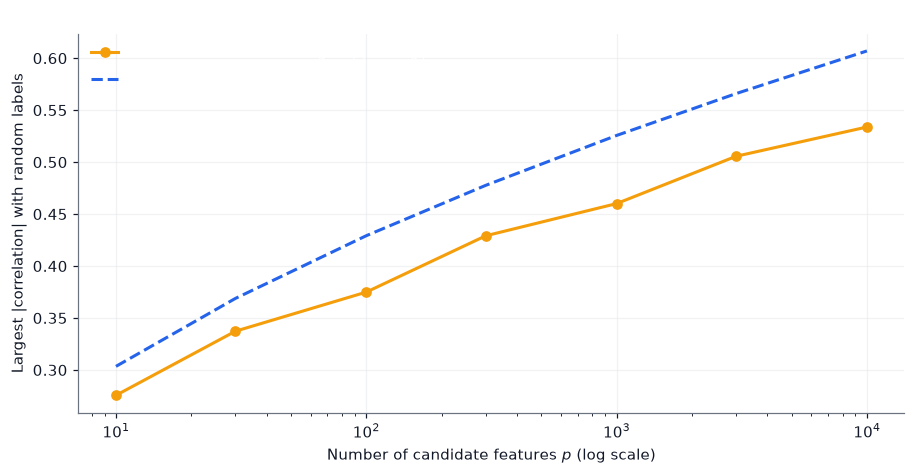

p = 10,000: simulated 0.534 | approximation 0.607


In [8]:
rng = np.random.default_rng(2)
n_s = 50
ps = [10, 30, 100, 300, 1000, 3000, 10000]
simulated, formula = [], []
for p in ps:
    maxima = []
    for _ in range(60):
        X_noise = rng.normal(size=(n_s, p))
        y_noise = rng.normal(size=n_s)                                   # labels independent of every feature
        Xc, yc = X_noise - X_noise.mean(0), y_noise - y_noise.mean()
        r = (Xc * yc[:, None]).sum(0) / (np.sqrt((Xc**2).sum(0)) * np.sqrt((yc**2).sum()))
        maxima.append(np.abs(r).max())
    simulated.append(np.mean(maxima)); formula.append(math.sqrt(2 * math.log(p) / n_s))

fig, ax = plt.subplots(figsize=(8.4, 4.4))
ax.semilogx(ps, simulated, "o-", color=COLORS["orange"], label="Simulation: mean of the largest |r| among $p$ noise features")
ax.semilogx(ps, formula, "--", color=COLORS["blue"], label=r"Approximation $\sqrt{2\ln p / n}$")
ax.set_xlabel("Number of candidate features $p$ (log scale)"); ax.set_ylabel("Largest |correlation| with random labels")
ax.set_title(f"With n = {n_s} samples, the best of many noise features looks informative"); ax.legend(loc="upper left")
finish(fig, "03_max_correlation_noise")
print("p = 10,000: simulated", round(simulated[-1], 3), "| approximation", round(formula[-1], 3))

### 6.2 Tools for the leakage experiments

To measure leakage we need a fast classifier and a pipeline in which **feature selection is explicitly part of the model**. We use a ridge-regularized linear classifier written in NumPy (closed form, so thousands of fits are quick):

1. **Selection:** keep the $k$ features with the largest ANOVA $F$-statistic, computed from the *training* samples of the fit,
$$F_j = \frac{\sum_c n_c(\bar{x}_{cj} - \bar{x}_j)^2/(C-1)}{\sum_c \sum_{i\in c}(x_{ij}-\bar{x}_{cj})^2/(N-C)} .$$
2. **Standardization** with training mean and standard deviation.
3. **Ridge classifier:** regress the one-hot class indicators on the features, $W = X^{\top}(XX^{\top} + \lambda I)^{-1}(Y - \bar{Y})$ (the *dual* form, efficient when $n < p$); the predicted class is the one with the highest score.

Everything that learns from data lives inside `fit_scores`, so calling it on a training fold can never see the test fold.

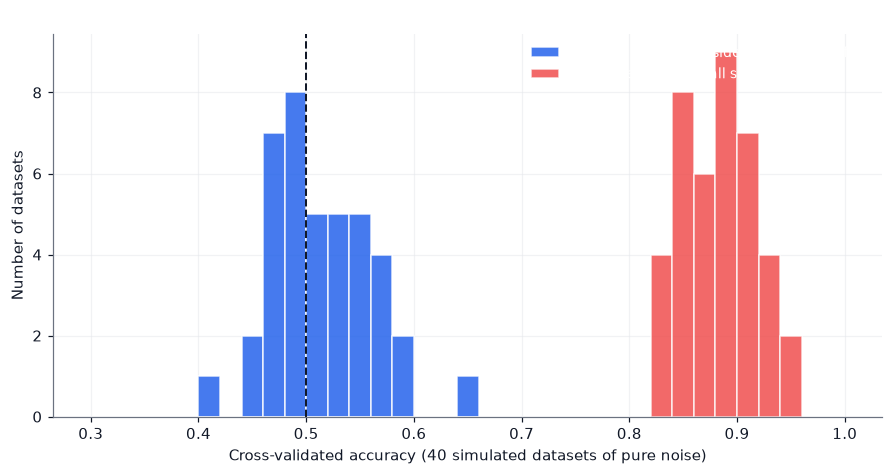

Mean CV accuracy -> correct pipeline: 0.511 | leaky pipeline: 0.882   (truth: 0.500)


In [9]:
def anova_f(X, y, n_classes):
    """ANOVA F-statistic of every column of X for the class labels y (vectorized)."""
    X = np.asarray(X, dtype=np.float64)
    N = len(y)
    onehot = np.eye(n_classes)[y]                                    # (N, C)
    counts = onehot.sum(axis=0)                                      # n_c
    means = np.divide(onehot.T @ X, counts[:, None], out=np.zeros((n_classes, X.shape[1])), where=counts[:, None] > 0)
    grand = X.mean(axis=0)
    ssb = (counts[:, None] * (means - grand) ** 2).sum(axis=0)
    ssw = (X ** 2).sum(axis=0) - (counts[:, None] * means ** 2).sum(axis=0)
    present = int((counts > 0).sum())
    return (ssb / max(present - 1, 1)) / (np.maximum(ssw, 0) / max(N - present, 1) + 1e-12)

def top_k_columns(X, y, n_classes, k):
    return np.argsort(-anova_f(X, y, n_classes))[:k]

def ridge_dual_scores(X_train, y_train, X_test, n_classes, lam):
    """Standardize with training statistics, fit a ridge classifier in dual form, return test scores."""
    mu, sd = X_train.mean(axis=0), X_train.std(axis=0) + 1e-8
    Xt, Xe = (X_train - mu) / sd, (X_test - mu) / sd
    Y = np.eye(n_classes)[y_train]; y_bar = Y.mean(axis=0)
    K = Xt @ Xt.T
    alpha = np.linalg.solve(K + lam * np.eye(len(Xt)), Y - y_bar)
    return (Xe @ Xt.T) @ alpha + y_bar

def fit_scores(X_train, y_train, X_test, n_classes, k=50, lam=10.0, columns=None):
    """Complete pipeline: (1) select features, (2) standardize, (3) ridge. If `columns` is given, the selection
    is NOT repeated (this is what a leaky protocol does with columns chosen on all the data)."""
    cols = top_k_columns(X_train, y_train, n_classes, k) if columns is None else columns
    return ridge_dual_scores(X_train[:, cols], y_train, X_test[:, cols], n_classes, lam)

def stratified_kfold(y, n_splits, seed):
    """Yield (train_idx, test_idx) for stratified k-fold cross-validation."""
    r = np.random.default_rng(seed)
    folds = [[] for _ in range(n_splits)]
    for c in np.unique(y):
        idx = r.permutation(np.flatnonzero(y == c))
        for i, j in enumerate(idx):
            folds[i % n_splits].append(j)
    all_idx = np.arange(len(y))
    for f in folds:
        test = np.array(sorted(f), dtype=int)
        yield np.setdiff1d(all_idx, test), test

def cv_accuracy(X, y, n_classes, n_splits=5, seed=0, k=50, lam=10.0, leaky=False):
    """Cross-validated accuracy. leaky=True selects the features ONCE on all the data (the classic mistake)."""
    leaky_cols = top_k_columns(X, y, n_classes, k) if leaky else None
    correct = 0
    for tr, te in stratified_kfold(y, n_splits, seed):
        scores = fit_scores(X[tr], y[tr], X[te], n_classes, k, lam, columns=leaky_cols)
        correct += np.sum(scores.argmax(axis=1) == y[te])
    return correct / len(y)

# --- Experiment on PURE NOISE: 100 samples, 5000 features, random binary labels. The true accuracy is 50%.
rng = np.random.default_rng(3)
leaky_acc, correct_acc = [], []
for rep in range(40):
    X_n = rng.normal(size=(100, 5000)).astype("float32")
    y_n = rng.permutation(np.repeat([0, 1], 50))
    leaky_acc.append(cv_accuracy(X_n, y_n, 2, seed=rep, k=20, lam=10.0, leaky=True))
    correct_acc.append(cv_accuracy(X_n, y_n, 2, seed=rep, k=20, lam=10.0, leaky=False))

fig, ax = plt.subplots(figsize=(8.2, 4.4))
bins = np.linspace(0.3, 1.0, 36)
ax.hist(correct_acc, bins=bins, color=COLORS["blue"], alpha=0.85, edgecolor="white", label="Correct: selection inside each training fold")
ax.hist(leaky_acc, bins=bins, color=COLORS["red"], alpha=0.8, edgecolor="white", label="Leaky: selection on all samples first")
ax.axvline(0.5, color=COLORS["dark"], linestyle="--", linewidth=1.3); ax.annotate("true accuracy = 0.5", (0.5, ax.get_ylim()[1] * 0.92), textcoords="offset points", xytext=(6, 0), fontsize=9)
ax.set_xlabel("Cross-validated accuracy (40 simulated datasets of pure noise)"); ax.set_ylabel("Number of datasets")
ax.set_title("Leakage turns noise into an impressive result"); ax.legend(loc="upper right")
finish(fig, "04_leakage_noise")
print(f"Mean CV accuracy -> correct pipeline: {np.mean(correct_acc):.3f} | leaky pipeline: {np.mean(leaky_acc):.3f}   (truth: 0.500)")

The **correct** pipeline gives accuracies scattered around the true value, 0.5 (some above, some below, as expected from a binomial with $n = 100$). The **leaky** pipeline reports far higher values *for data that contain no signal at all*. Nothing in the leaky procedure looks wrong: it uses cross-validation, the test folds are never used for training the classifier — only the feature selection saw them.

## 7. Metrics for binary decisions

For a binary problem with a "positive" class (here: a rare cancer type), the predictions fall into four cells:

| | Predicted positive | Predicted negative |
|---|---|---|
| **Actually positive** | TP | FN |
| **Actually negative** | FP | TN |

$$
\text{Sensitivity (recall, TPR)} = \frac{TP}{TP+FN}, \qquad
\text{Specificity (TNR)} = \frac{TN}{TN+FP}, \qquad
\text{PPV (precision)} = \frac{TP}{TP+FP}, \qquad
\text{NPV} = \frac{TN}{TN+FN},
$$

$$
F_\beta = \frac{(1+\beta^2)\,PPV\cdot\text{Sens}}{\beta^2\,PPV + \text{Sens}}, \qquad
\text{Balanced accuracy} = \frac{\text{Sens}+\text{Spec}}{2}, \qquad
\text{MCC} = \frac{TP\cdot TN - FP\cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}} .
$$

$F_1$ ($\beta = 1$) is the harmonic mean of precision and recall; $\beta = 2$ weights recall more, $\beta = 0.5$ weights precision more. Note that $F_\beta$ **ignores TN** entirely.

### 7.1 Sensitivity and specificity do not depend on prevalence — PPV does

Let $\pi$ be the **prevalence** (the fraction of positives). By Bayes' theorem:

$$
PPV = \mathbb{P}(\text{positive}\mid\text{predicted positive})
= \frac{\text{Sens}\cdot\pi}{\text{Sens}\cdot\pi + (1-\text{Spec})(1-\pi)} .
$$

For a rare condition ($\pi$ small), even a small false-positive rate $(1-\text{Spec})$ produces many more false alarms than true detections, so the PPV is low. A classifier with 90% sensitivity and 90% specificity has PPV $\approx 0.5$ at $\pi = 0.1$ and only $\approx 0.08$ at $\pi = 0.01$.

In [10]:
def binary_confusion(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).astype(bool), np.asarray(y_pred).astype(bool)
    return int(np.sum(y_true & y_pred)), int(np.sum(~y_true & y_pred)), int(np.sum(y_true & ~y_pred)), int(np.sum(~y_true & ~y_pred))

def safe_div(a, b):
    return a / b if b > 0 else float("nan")

def binary_metrics(y_true, y_pred, beta=1.0):
    tp, fp, fn, tn = binary_confusion(y_true, y_pred)
    sens, spec, ppv, npv = safe_div(tp, tp + fn), safe_div(tn, tn + fp), safe_div(tp, tp + fp), safe_div(tn, tn + fn)
    f_beta = safe_div((1 + beta**2) * ppv * sens, beta**2 * ppv + sens) if not (math.isnan(ppv) or math.isnan(sens)) else float("nan")
    denom = math.sqrt(float((tp + fp)) * (tp + fn) * (tn + fp) * (tn + fn))
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn, "sensitivity": sens, "specificity": spec, "PPV": ppv, "NPV": npv,
            "F1": f_beta, "accuracy": (tp + tn) / (tp + tn + fp + fn), "balanced accuracy": (sens + spec) / 2,
            "MCC": (tp * tn - fp * fn) / denom if denom > 0 else 0.0}

# The accuracy paradox: a useless classifier for a rare class.
prevalence = 78 / 801
y_demo = np.zeros(1000, dtype=int); y_demo[:int(round(prevalence * 1000))] = 1
always_negative = np.zeros_like(y_demo)
m = binary_metrics(y_demo, always_negative)
print(f"Prevalence {prevalence:.3f}. A classifier that ALWAYS answers 'negative':")
print(f"  accuracy = {m['accuracy']:.3f}   sensitivity = {m['sensitivity']:.3f}   F1 = {m['F1']}   MCC = {m['MCC']:.3f}")

Prevalence 0.097. A classifier that ALWAYS answers 'negative':
  accuracy = 0.903   sensitivity = 0.000   F1 = nan   MCC = 0.000


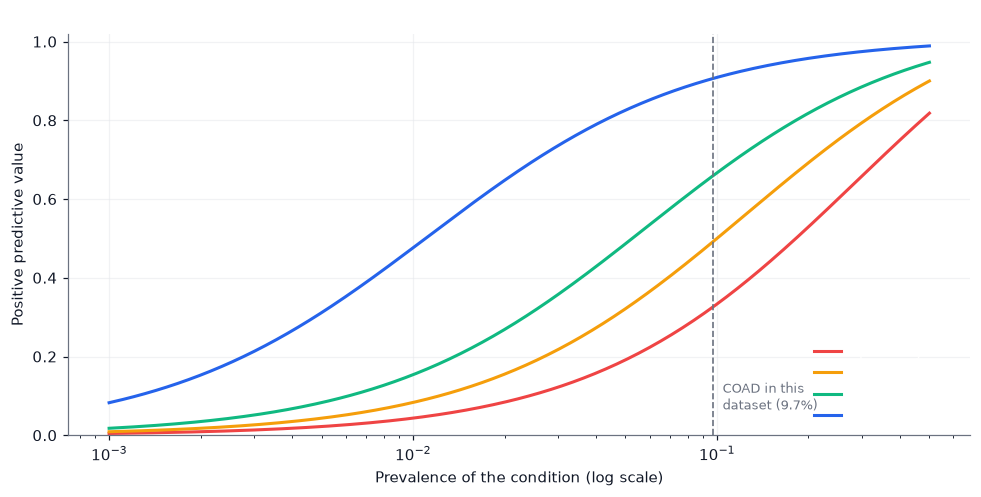

sensitivity 0.9, specificity 0.9, prevalence 0.1: PPV = 0.500
sensitivity 0.9, specificity 0.9, prevalence 0.01: PPV = 0.083
sensitivity 0.9, specificity 0.99, prevalence 0.1: PPV = 0.909
sensitivity 0.9, specificity 0.99, prevalence 0.01: PPV = 0.476


In [11]:
prevalences = np.geomspace(0.001, 0.5, 300)
fig, ax = plt.subplots(figsize=(9, 4.6))
for spec, color in [(0.80, COLORS["red"]), (0.90, COLORS["orange"]), (0.95, COLORS["green"]), (0.99, COLORS["blue"])]:
    sens = 0.90
    ppv = sens * prevalences / (sens * prevalences + (1 - spec) * (1 - prevalences))
    ax.semilogx(prevalences, ppv, color=color, label=f"specificity {spec:.2f}")
ax.axvline(78 / 801, color=COLORS["gray"], linestyle="--", linewidth=1.1)
ax.annotate("COAD in this\ndataset (9.7%)", (78 / 801, 0.05), textcoords="offset points", xytext=(6, 4), fontsize=8.5, color=COLORS["gray"])
ax.set_xlabel("Prevalence of the condition (log scale)"); ax.set_ylabel("Positive predictive value")
ax.set_title("With sensitivity 0.90, the PPV collapses for rare conditions"); ax.legend(loc="lower right"); ax.set_ylim(0, 1.02)
finish(fig, "05_ppv_prevalence")
for spec in (0.9, 0.99):
    for pi in (0.1, 0.01):
        print(f"sensitivity 0.9, specificity {spec}, prevalence {pi}: PPV = {0.9 * pi / (0.9 * pi + (1 - spec) * (1 - pi)):.3f}")

## 8. ROC curves, AUC, and precision–recall curves

Many classifiers produce a **score** $s(x)$ (a probability or any monotone function of it), and the decision is "positive if $s(x) \ge t$". Changing the threshold $t$ trades sensitivity for specificity.

### 8.1 The ROC curve

For each threshold $t$ compute

$$
\operatorname{TPR}(t) = \mathbb{P}(s \ge t \mid \text{positive}), \qquad
\operatorname{FPR}(t) = \mathbb{P}(s \ge t \mid \text{negative}) .
$$

The **ROC curve** plots $\operatorname{TPR}$ against $\operatorname{FPR}$ as $t$ goes from $+\infty$ (point $(0,0)$) to $-\infty$ (point $(1,1)$). A random scorer follows the diagonal. The **area under the curve (AUC)** is a one-number summary.

### 8.2 AUC is a probability

Let $S^{+}$ be the score of a random positive and $S^{-}$ the score of an independent random negative. Then

$$
\text{AUC} = \mathbb{P}(S^{+} > S^{-}) + \tfrac{1}{2}\,\mathbb{P}(S^{+} = S^{-}) .
$$

*Proof sketch:* $\text{AUC} = \int_0^1 \operatorname{TPR}\, d(\operatorname{FPR})$; writing $\operatorname{FPR}(t) = \mathbb{P}(S^{-} \ge t)$, the integral becomes $\int \mathbb{P}(S^{+} \ge t)\, f_{S^{-}}(t)\, dt = \mathbb{P}(S^{+} \ge S^{-})$. (With ties, the trapezoidal rule gives the half-weight for ties.) This is also the **Mann–Whitney $U$ statistic**: $\text{AUC} = U/(n_+ n_-)$, where $U = R_+ - n_+(n_+ + 1)/2$ and $R_+$ is the sum of the ranks of the positive scores. So AUC depends only on the *ranking* of the scores, **not** on their calibration.

We implement the ROC curve, the trapezoidal area, the rank-based formula, and the brute-force pairwise probability, and check that they agree.

### 8.3 Precision–recall curves

The **PR curve** plots $PPV(t)$ against $\operatorname{Sens}(t)$. Its summary is the **average precision**

$$
AP = \sum_{n} (R_n - R_{n-1})\,P_n,
$$

where $(P_n, R_n)$ are the precision and recall at the $n$-th threshold. A random scorer has precision equal to the prevalence $\pi$ at all recalls, so the baseline of the PR curve is a horizontal line at $\pi$ (unlike the fixed diagonal of the ROC curve).

In [12]:
def roc_curve_np(y_true, score):
    y_true = np.asarray(y_true).astype(bool)
    order = np.argsort(-score, kind="stable")
    s, yt = np.asarray(score)[order], y_true[order]
    tps, fps = np.cumsum(yt), np.cumsum(~yt)
    distinct = np.r_[np.flatnonzero(np.diff(s)), len(s) - 1]          # last index of each distinct score
    tpr = np.r_[0.0, tps[distinct] / tps[-1]]
    fpr = np.r_[0.0, fps[distinct] / fps[-1]]
    thresholds = np.r_[np.inf, s[distinct]]
    return fpr, tpr, thresholds

def auc_trapezoid(x, y):
    return float(np.sum((x[1:] - x[:-1]) * (y[1:] + y[:-1]) / 2))

def average_ranks(values):
    order = np.argsort(values, kind="stable"); ranks = np.empty(len(values)); sorted_vals = values[order]
    i = 0
    while i < len(values):
        j = i
        while j + 1 < len(values) and sorted_vals[j + 1] == sorted_vals[i]:
            j += 1
        ranks[order[i:j + 1]] = (i + j) / 2 + 1; i = j + 1
    return ranks

def auc_rank(y_true, score):
    y_true = np.asarray(y_true).astype(bool); n_pos, n_neg = y_true.sum(), (~y_true).sum()
    ranks = average_ranks(np.asarray(score, dtype=float))
    return float((ranks[y_true].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))

def auc_pairwise(y_true, score):
    y_true = np.asarray(y_true).astype(bool); pos, neg = np.asarray(score)[y_true], np.asarray(score)[~y_true]
    return float(np.mean((pos[:, None] > neg[None, :]) + 0.5 * (pos[:, None] == neg[None, :])))

def pr_curve_np(y_true, score):
    y_true = np.asarray(y_true).astype(bool)
    order = np.argsort(-score, kind="stable"); s, yt = np.asarray(score)[order], y_true[order]
    tps, fps = np.cumsum(yt), np.cumsum(~yt)
    distinct = np.r_[np.flatnonzero(np.diff(s)), len(s) - 1]
    precision = tps[distinct] / (tps[distinct] + fps[distinct]); recall = tps[distinct] / tps[-1]
    return np.r_[1.0, precision], np.r_[0.0, recall], np.r_[np.inf, s[distinct]]

def average_precision(y_true, score):
    precision, recall, _ = pr_curve_np(y_true, score)
    return float(np.sum((recall[1:] - recall[:-1]) * precision[1:]))

# Verification: three ways to compute the AUC agree, including with tied scores.
rng = np.random.default_rng(4)
y_chk = (rng.random(300) < 0.3).astype(int)
s_chk = np.round(rng.normal(loc=1.0 * y_chk, scale=1.0), 1)                 # rounding creates ties on purpose
fpr_c, tpr_c, _ = roc_curve_np(y_chk, s_chk)
print("AUC (trapezoid)   :", round(auc_trapezoid(fpr_c, tpr_c), 6))
print("AUC (rank / U)    :", round(auc_rank(y_chk, s_chk), 6))
print("AUC (pairwise P)  :", round(auc_pairwise(y_chk, s_chk), 6))
assert np.allclose([auc_trapezoid(fpr_c, tpr_c), auc_rank(y_chk, s_chk)], auc_pairwise(y_chk, s_chk))
# AUC only depends on ranking: any increasing transformation of the score leaves it unchanged.
print("AUC after exp(score) transformation:", round(auc_rank(y_chk, np.exp(s_chk)), 6))

AUC (trapezoid)   : 0.780214
AUC (rank / U)    : 0.780214
AUC (pairwise P)  : 0.780214
AUC after exp(score) transformation: 0.780214


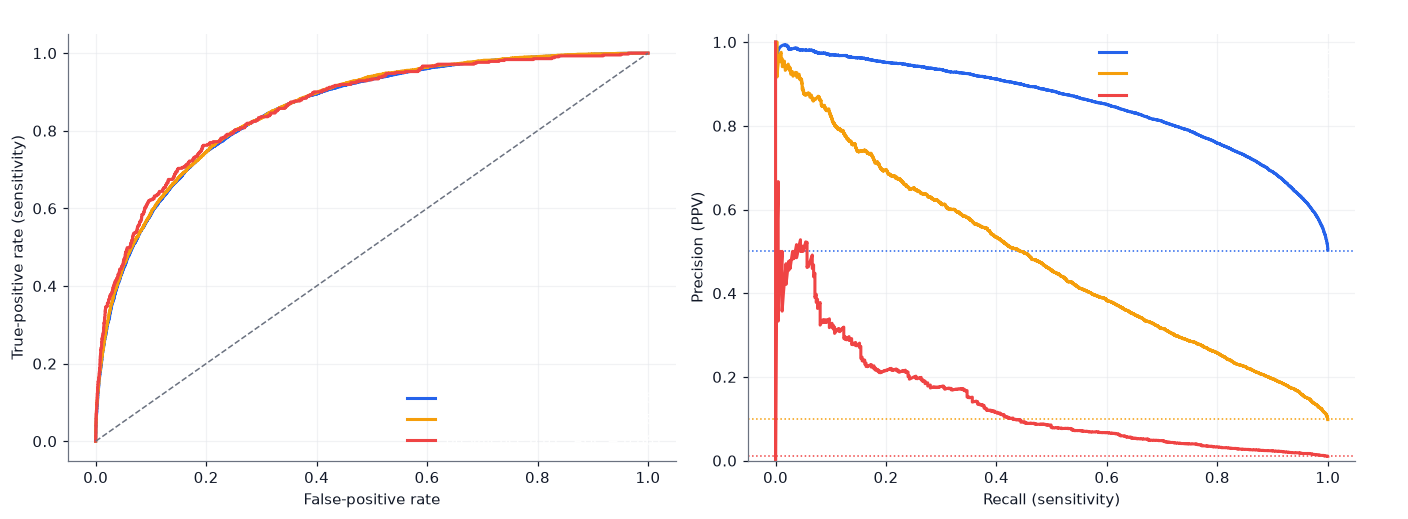

In [13]:
# ROC curves do not change with prevalence; precision-recall curves do.
rng = np.random.default_rng(5)
def make_scores(prev, n=40000):
    y = (rng.random(n) < prev).astype(int)
    return y, rng.normal(loc=1.5 * y, scale=1.0)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
rows = []
for prev, color in [(0.5, COLORS["blue"]), (0.1, COLORS["orange"]), (0.01, COLORS["red"])]:
    y_s, s_s = make_scores(prev)
    fpr, tpr, _ = roc_curve_np(y_s, s_s); prec, rec, _ = pr_curve_np(y_s, s_s)
    auc, ap = auc_rank(y_s, s_s), average_precision(y_s, s_s)
    axes[0].plot(fpr, tpr, color=color, label=f"prevalence {prev:g}:  AUC = {auc:.3f}")
    axes[1].plot(rec, prec, color=color, label=f"prevalence {prev:g}:  AP = {ap:.3f}")
    axes[1].axhline(prev, color=color, linestyle=":", linewidth=1)
    rows.append((prev, auc, ap))
axes[0].plot([0, 1], [0, 1], color=COLORS["gray"], linestyle="--", linewidth=1)
axes[0].set_xlabel("False-positive rate"); axes[0].set_ylabel("True-positive rate (sensitivity)"); axes[0].set_title("ROC: identical for all prevalences"); axes[0].legend(loc="lower right")
axes[1].set_xlabel("Recall (sensitivity)"); axes[1].set_ylabel("Precision (PPV)"); axes[1].set_title("Precision\u2013recall: collapses as prevalence falls (dotted = chance)"); axes[1].legend(loc="upper right")
axes[1].set_ylim(0, 1.02)
finish(fig, "06_roc_vs_pr_prevalence")

The **same scorer** (same separation between positives and negatives) has the same ROC curve and AUC at every prevalence, because TPR and FPR are each computed within one class. The precision, however, mixes the two classes and so depends on how many negatives there are. For rare positives a high AUC can coexist with a poor precision at every useful recall — which is why PR curves and the average precision are the more informative summary under strong imbalance, and why the *chance level* of AP is the prevalence, not 0.5.

## 9. Thresholds, costs, and calibration

### 9.1 Choosing the threshold

The AUC says how well a score *ranks*; deploying a classifier requires a **threshold**. Common criteria:

- **Youden's $J$**: maximize $\text{Sens}+\text{Spec}-1$ (the point of the ROC curve farthest above the diagonal);
- **maximum $F_1$** on the validation set;
- a **cost-based** threshold.

Whatever the criterion, the threshold must be chosen on **validation** data (or in the training folds), never on the test set.

### 9.2 Cost-sensitive threshold (derivation)

Suppose a missed positive costs $c_{FN}$ and a false alarm costs $c_{FP}$, and the model outputs a **calibrated** probability $p = \mathbb{P}(\text{positive}\mid x)$. The expected costs of the two decisions are

$$
\text{predict positive: } (1-p)\,c_{FP}, \qquad \text{predict negative: } p\,c_{FN}.
$$

Predicting positive is better when $(1-p)c_{FP} \le p\,c_{FN}$, that is

$$
p \;\ge\; p^{*} = \frac{c_{FP}}{c_{FP}+c_{FN}} .
$$

If missing a cancer is 5 times worse than a false alarm, $p^{*} = 1/6 \approx 0.17$: the threshold is far below 0.5. This rule is only optimal if the probabilities are **calibrated**.

### 9.3 Calibration

A model is **calibrated** if, among the patients to whom it assigns probability $p$, a fraction $p$ are positive. Tools:

$$
\text{Brier score} = \frac{1}{n}\sum_i (p_i - y_i)^2, \qquad
\text{ECE} = \sum_{b=1}^{B}\frac{n_b}{n}\,\big|\,\overline{y}_b - \overline{p}_b\,\big| ,
$$

where the ECE (expected calibration error) averages the gap between the observed frequency $\overline{y}_b$ and the mean predicted probability $\overline{p}_b$ in $B$ probability bins. A **reliability diagram** plots $\overline{y}_b$ against $\overline{p}_b$. Because AUC depends only on the ranking, **a model can have a perfect AUC and terrible calibration**. We illustrate both ideas by simulation.

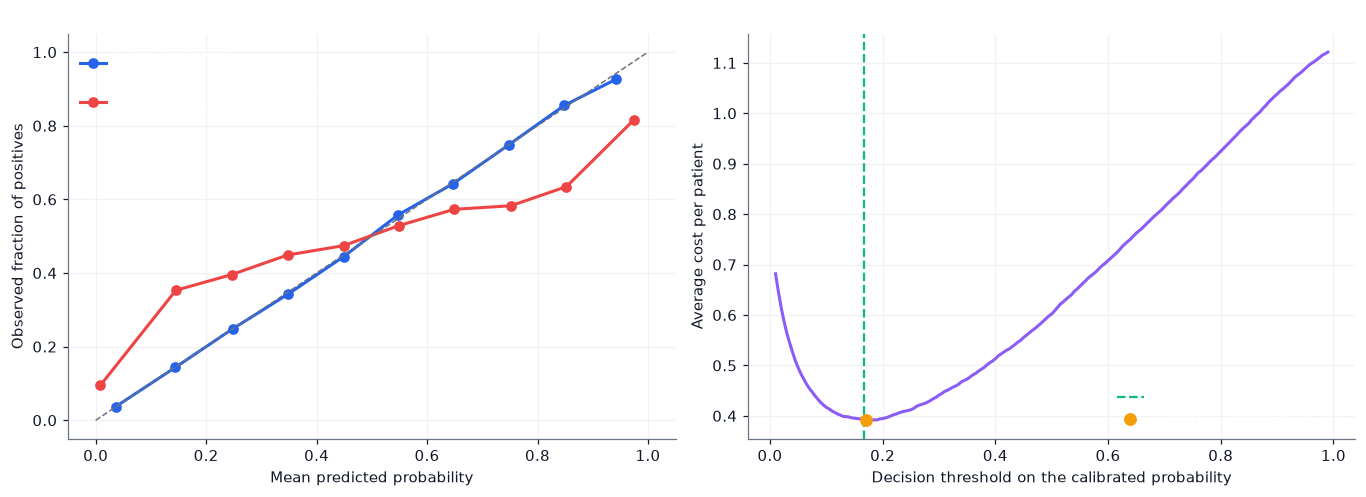

AUC of both models: 0.8694 | 0.8694  (identical: AUC ignores calibration)


In [14]:
def reliability_bins(y_true, prob, n_bins=10):
    y_true, prob = np.asarray(y_true, dtype=float), np.asarray(prob, dtype=float)
    edges = np.linspace(0, 1, n_bins + 1)
    which = np.clip(np.digitize(prob, edges[1:-1]), 0, n_bins - 1)
    rows = [(prob[which == b].mean(), y_true[which == b].mean(), int((which == b).sum())) for b in range(n_bins) if np.any(which == b)]
    return np.array(rows)

def brier_score(y_true, prob):
    return float(np.mean((np.asarray(prob) - np.asarray(y_true)) ** 2))

def expected_calibration_error(y_true, prob, n_bins=10):
    rows = reliability_bins(y_true, prob, n_bins)
    return float(np.sum(rows[:, 2] / rows[:, 2].sum() * np.abs(rows[:, 1] - rows[:, 0])))

sigmoid = lambda t: 1 / (1 + np.exp(-t))
rng = np.random.default_rng(6)
x_sim = rng.normal(size=60000)
p_true = sigmoid(2 * x_sim - 2)                                 # the true probability of being positive
y_sim = (rng.random(len(x_sim)) < p_true).astype(int)
p_overconfident = sigmoid(6 * x_sim - 6)                         # same ranking, much too extreme

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for prob, color, label in [(p_true, COLORS["blue"], "Calibrated model"), (p_overconfident, COLORS["red"], "Overconfident model (same ranking)")]:
    rows = reliability_bins(y_sim, prob)
    axes[0].plot(rows[:, 0], rows[:, 1], "o-", color=color, label=f"{label}\nBrier {brier_score(y_sim, prob):.3f}, ECE {expected_calibration_error(y_sim, prob):.3f}")
axes[0].plot([0, 1], [0, 1], color=COLORS["gray"], linestyle="--", linewidth=1)
axes[0].set_xlabel("Mean predicted probability"); axes[0].set_ylabel("Observed fraction of positives"); axes[0].set_title("Reliability diagram"); axes[0].legend(loc="upper left", fontsize=8.5)

# Expected cost against threshold when a missed positive is 5x worse than a false alarm.
c_fp, c_fn = 1.0, 5.0
thresholds = np.linspace(0.01, 0.99, 197)
costs = [np.mean(np.where(p_true >= t, (1 - y_sim) * c_fp, y_sim * c_fn)) for t in thresholds]
best_t = thresholds[int(np.argmin(costs))]
axes[1].plot(thresholds, costs, color=COLORS["purple"])
axes[1].axvline(c_fp / (c_fp + c_fn), color=COLORS["green"], linestyle="--", linewidth=1.5, label=f"Theory: $p^*$ = {c_fp / (c_fp + c_fn):.3f}")
axes[1].scatter([best_t], [min(costs)], color=COLORS["orange"], zorder=5, s=55, label=f"Empirical minimum: {best_t:.3f}")
axes[1].set_xlabel("Decision threshold on the calibrated probability"); axes[1].set_ylabel("Average cost per patient")
axes[1].set_title("The cost-optimal threshold is far below 0.5"); axes[1].legend()
finish(fig, "07_calibration_and_cost")
print("AUC of both models:", round(auc_rank(y_sim, p_true), 4), "|", round(auc_rank(y_sim, p_overconfident), 4), " (identical: AUC ignores calibration)")

## 10. Cross-validation, the winner's curse, and comparing models

### 10.1 $k$-fold cross-validation

Split the data into $k$ folds. For each fold $j$, train on the other $k-1$ folds and compute the performance $\hat{A}_j$ on fold $j$. The CV estimate is the average $\hat{A}_{CV} = \frac{1}{k}\sum_j \hat{A}_j$. Properties:

- It uses all samples for testing and (almost) all for training, so it is **more efficient** than a single split.
- It is **slightly pessimistic**: each model is trained on $\frac{k-1}{k}n$ samples, fewer than the final model.
- Its **variance** has two parts: which samples fall in which fold, and the instability of the learning algorithm. **Repeating** the CV with different random partitions (repeated CV) reduces the first part.
- The fold estimates are **not independent** (the training sets overlap strongly), so the naive standard error $s/\sqrt{k}$ is too small.
- Everything that learns from the data — standardization, feature selection, hyperparameter choice — must happen **inside** each training fold.

### 10.2 The winner's curse

If we try $M$ models and report the best CV score, the report is biased upwards. Suppose the $M$ estimates are independent with the same true accuracy $A$ and standard deviation $\sigma \approx \sqrt{A(1-A)/n}$. The expected maximum is

$$
\mathbb{E}\big[\max_m \hat{A}_m\big] \;\approx\; A + \sigma\sqrt{2\ln M} .
$$

With $n = 100$, $A = 0.5$ (no skill), and $M = 50$ models, the best model looks about $0.5 + 0.05\cdot 2.8 \approx 0.64$ accurate (the simulation below gives a slightly smaller value, because the approximation slightly over-estimates the expected maximum). The remedy is **nested cross-validation**: an *inner* CV chooses the model or hyperparameters, an *outer* CV evaluates that **whole procedure** on data the inner loop never saw.

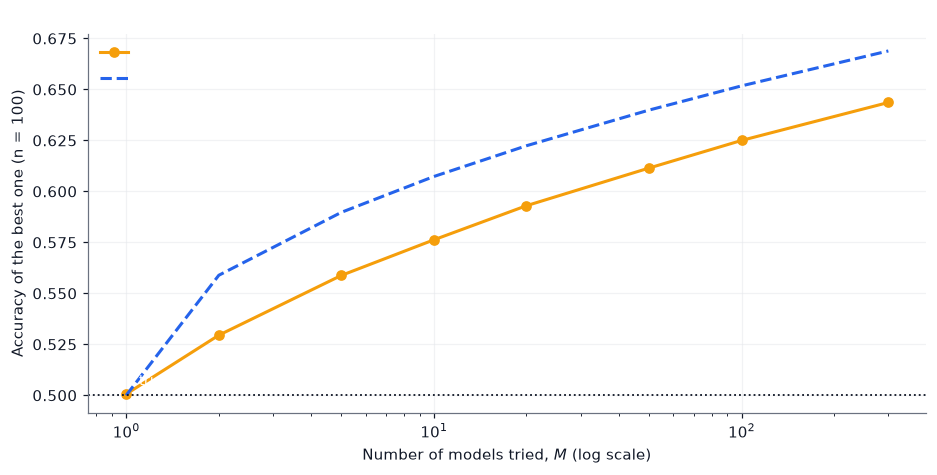

M = 50: simulated 0.611 | approximation 0.64


In [15]:
rng = np.random.default_rng(7)
n_eval, A_true = 100, 0.5
sigma = math.sqrt(A_true * (1 - A_true) / n_eval)
Ms = [1, 2, 5, 10, 20, 50, 100, 300]
best_sim, best_formula = [], []
for M in Ms:
    best_sim.append(np.mean([rng.binomial(n_eval, A_true, size=M).max() / n_eval for _ in range(4000)]))
    best_formula.append(A_true + sigma * math.sqrt(2 * math.log(M)) if M > 1 else A_true)

fig, ax = plt.subplots(figsize=(8.6, 4.4))
ax.semilogx(Ms, best_sim, "o-", color=COLORS["orange"], label="Simulation: best of $M$ no-skill models")
ax.semilogx(Ms, best_formula, "--", color=COLORS["blue"], label=r"$A + \sigma\sqrt{2\ln M}$")
ax.axhline(A_true, color=COLORS["dark"], linestyle=":", linewidth=1.2); ax.annotate("true accuracy (no skill)", (1.1, A_true + 0.005), fontsize=9)
ax.set_xlabel("Number of models tried, $M$ (log scale)"); ax.set_ylabel("Accuracy of the best one (n = 100)")
ax.set_title("Reporting the best of many models is optimistic"); ax.legend(loc="upper left")
finish(fig, "08_winners_curse")
print("M = 50: simulated", round(best_sim[Ms.index(50)], 3), "| approximation", round(best_formula[Ms.index(50)], 3))

### 10.3 Comparing two models on the same data

Models evaluated on the **same** samples make correlated errors, so comparisons must be **paired**.

**McNemar's test** (one test set). Let $b$ be the number of samples that model A gets right and model B wrong, and $c$ the reverse. Under the null hypothesis "the models have the same error rate", each discordant sample is equally likely to be of either kind, so $b \sim \operatorname{Binomial}(b+c, \tfrac{1}{2})$ and the exact two-sided $p$-value is

$$
p = \min\Big(1,\; 2\sum_{i=0}^{\min(b,c)}\binom{b+c}{i}\,2^{-(b+c)}\Big).
$$

Only the discordant samples matter.

**Corrected resampled $t$-test** (repeated cross-validation; Nadeau and Bengio, 2003). With $J$ train/test resamples, paired differences $d_1,\dots,d_J$ (model A minus model B), mean $\bar{d}$ and sample variance $s_d^2$:

$$
t = \frac{\bar{d}}{\sqrt{\left(\frac{1}{J} + \frac{n_{\text{test}}}{n_{\text{train}}}\right) s_d^2}}, \qquad t \sim t_{J-1}\ \text{(approximately)} .
$$

The naive $t$-test would use $1/J$ only and ignores that the resamples overlap; the extra term $n_{\text{test}}/n_{\text{train}}$ corrects the resulting overconfidence.

**Permutation test** (is the model better than chance at all?). Shuffle the labels many times, repeat the *entire* evaluation procedure on each shuffled dataset, and compare the observed score with this null distribution: $p = (1 + \#\{\text{null} \ge \text{observed}\})/(1+B)$.

In [16]:
def mcnemar_exact(correct_a, correct_b):
    """Exact McNemar test from per-sample correctness indicators of two models on the same samples."""
    correct_a, correct_b = np.asarray(correct_a, dtype=bool), np.asarray(correct_b, dtype=bool)
    b, c = int(np.sum(correct_a & ~correct_b)), int(np.sum(~correct_a & correct_b))
    n = b + c
    if n == 0:
        return b, c, 1.0
    tail = sum(comb(n, i) for i in range(min(b, c) + 1)) / 2**n
    return b, c, min(1.0, 2 * tail)

def student_t_two_sided_p(t_stat, df):
    """Two-sided p-value of Student's t distribution by numerical integration of the density."""
    t_abs = abs(t_stat)
    norm = math.exp(lgamma((df + 1) / 2) - lgamma(df / 2)) / math.sqrt(df * math.pi)
    xs = np.linspace(t_abs, t_abs + 400.0, 400001)
    pdf = norm * (1 + xs**2 / df) ** (-(df + 1) / 2)
    integrate = getattr(np, "trapezoid", None) or np.trapz              # NumPy 2 renamed trapz
    return float(min(1.0, 2 * integrate(pdf, xs)))

def corrected_resampled_ttest(differences, n_train, n_test):
    d = np.asarray(differences, dtype=float); J = len(d)
    var = d.var(ddof=1)
    if var == 0:
        return float("inf") if d.mean() != 0 else 0.0, 0.0 if d.mean() != 0 else 1.0
    t_stat = d.mean() / math.sqrt((1 / J + n_test / n_train) * var)
    return float(t_stat), student_t_two_sided_p(t_stat, J - 1)

# Small checks. McNemar: b = 12, c = 3 -> exact p = 2 * P(X <= 3), X ~ Binomial(15, 0.5)
b_, c_, p_ = mcnemar_exact(np.r_[np.ones(12), np.zeros(3), np.ones(20)], np.r_[np.zeros(12), np.ones(3), np.ones(20)])
print(f"McNemar example: b={b_}, c={c_}, exact p = {p_:.4f}  (hand computation: {2 * sum(comb(15, i) for i in range(4)) / 2**15:.4f})")
# Student t: for 10 degrees of freedom the two-sided 5% critical value is 2.228
print("p-value at t = 2.228 with 10 degrees of freedom:", round(student_t_two_sided_p(2.228, 10), 4), "(expected about 0.05)")

McNemar example: b=12, c=3, exact p = 0.0352  (hand computation: 0.0352)
p-value at t = 2.228 with 10 degrees of freedom: 0.05 (expected about 0.05)


# Part II — Experiments on tumour gene expression

## 11. The dataset and the "pilot cohort" experiment

We use the same data as Notebook 06 (*Gene expression cancer RNA-Seq*, Fiorini 2016, UCI, CC BY 4.0; 801 tumours, 20,531 genes, five cancer types BRCA, KIRC, LUAD, PRAD, COAD). The cell below looks for `data.csv` and `labels.csv` in `data/tcga_pancan/` (download or manual placement, exactly as in Notebook 06).

### 11.1 Measuring the quality of evaluation methods

In real life, you never know the true performance of your model on future patients. Here we can **simulate** that situation:

1. Draw a small **development cohort** of $n_{dev}$ patients (stratified random sample). This is all the data a research group would have.
2. Build and evaluate a model using the development cohort only, with different **evaluation protocols**. Each protocol gives an *estimate* of performance.
3. Train the model on the *whole* development cohort and measure its performance on **all the other patients** ($801 - n_{dev}$ of them). This is the "truth" that the protocols try to estimate.
4. Repeat with many different cohorts and study the **distribution of (estimate − truth)**: its mean is the protocol's **bias**, its spread is its **variance**.

The model in these experiments is the pipeline of Section 6.2: ANOVA feature selection ($k = 50$ genes) → standardization → ridge classifier, all fitted *inside* each training set.

In [19]:

import os
import tarfile
import tempfile
import urllib.request
import shutil
import pandas as pd

GENE_DIR = os.path.join("data", "tcga_pancan")
GENE_ARCHIVE = os.path.join(
    GENE_DIR, "TCGA-PANCAN-HiSeq-801x20531.tar.gz"
)
GENE_URL = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/00401/"
    "TCGA-PANCAN-HiSeq-801x20531.tar.gz"
)


def _find_csvs(root):
    found = {}

    for dirpath, _, files in os.walk(root):
        for filename in files:
            if filename in ("data.csv", "labels.csv"):
                found[filename] = os.path.join(dirpath, filename)

    return found


def _validate_archive(archive_path):
    """Check gzip/tar integrity and reject unsafe archive members."""

    with tarfile.open(archive_path, "r:gz") as tar:
        members = tar.getmembers()

        for member in members:
            name = member.name.replace("\\", "/")

            # Reject absolute paths and Windows drive paths
            if (
                name.startswith("/")
                or (len(name) >= 2 and name[1] == ":")
            ):
                raise RuntimeError(
                    f"Unsafe archive path: {member.name}"
                )

            # Reject symbolic and hard links
            if member.issym() or member.islnk():
                raise RuntimeError(
                    f"Archive links are not allowed: {member.name}"
                )

            target = os.path.realpath(
                os.path.join(GENE_DIR, name)
            )

            if os.path.commonpath(
                [os.path.realpath(GENE_DIR), target]
            ) != os.path.realpath(GENE_DIR):
                raise RuntimeError(
                    f"Unsafe archive path: {member.name}"
                )

        return len(members)


def _download_archive():
    """Download to a temporary file and replace only after validation."""

    fd, temp_path = tempfile.mkstemp(
        suffix=".tar.gz",
        dir=GENE_DIR
    )
    os.close(fd)

    try:
        print("Downloading TCGA-PANCAN dataset...")

        request = urllib.request.Request(
            GENE_URL,
            headers={"User-Agent": "Mozilla/5.0"}
        )

        with urllib.request.urlopen(request, timeout=60) as response:
            with open(temp_path, "wb") as output:
                shutil.copyfileobj(response, output)

        size_mb = os.path.getsize(temp_path) / (1024 ** 2)
        print(f"Downloaded: {size_mb:.2f} MB")

        member_count = _validate_archive(temp_path)

        if member_count == 0:
            raise RuntimeError("Downloaded archive is empty.")

        os.replace(temp_path, GENE_ARCHIVE)

        print("Download and archive validation successful.")

    except Exception as error:
        if os.path.exists(temp_path):
            os.remove(temp_path)

        raise RuntimeError(
            f"Dataset download or validation failed: {error}"
        ) from error


def _safe_extract(archive_path, root):
    """Extract a previously validated archive."""

    with tarfile.open(archive_path, "r:gz") as tar:
        tar.extractall(root)


def load_gene_expression():
    os.makedirs(GENE_DIR, exist_ok=True)

    found = _find_csvs(GENE_DIR)

    if len(found) < 2:

        # Download if missing
        if not os.path.exists(GENE_ARCHIVE):
            _download_archive()

        # Validate existing archive; redownload if corrupted
        else:
            try:
                _validate_archive(GENE_ARCHIVE)

            except (tarfile.TarError, EOFError, OSError, RuntimeError):
                print("Existing archive is corrupted. Redownloading...")

                os.remove(GENE_ARCHIVE)
                _download_archive()

        # Extract archive
        print("Extracting dataset...")
        _safe_extract(GENE_ARCHIVE, GENE_DIR)

        found = _find_csvs(GENE_DIR)

    if "data.csv" not in found or "labels.csv" not in found:
        raise FileNotFoundError(
            "Could not find both data.csv and labels.csv "
            f"inside {GENE_DIR}"
        )

    print("Loading expression matrix...")

    expression = pd.read_csv(
        found["data.csv"],
        index_col=0
    )

    labels = pd.read_csv(
        found["labels.csv"],
        index_col=0
    )["Class"]

    assert expression.index.equals(labels.index), (
        "Sample IDs of data.csv and labels.csv do not match."
    )

    return expression, labels


# Load dataset
expression_df, labels_series = load_gene_expression()

print(
    "Expression matrix:", expression_df.shape,
    "| Labels:", labels_series.shape
)


Loading expression matrix...
Expression matrix: (801, 20531) | Labels: (801,)


In [20]:
def confusion_matrix_np(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm

def summary_metrics(cm):
    """Accuracy, macro-F1 (over classes present in the true labels), and multiclass MCC."""
    cm = np.asarray(cm, dtype=float)
    tp, predicted, support = np.diag(cm), cm.sum(axis=0), cm.sum(axis=1)
    precision = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted > 0)
    recall = np.divide(tp, support, out=np.zeros_like(tp), where=support > 0)
    denom = precision + recall
    f1 = np.divide(2 * precision * recall, denom, out=np.zeros_like(tp), where=denom > 0)
    present = support > 0
    total = cm.sum()
    d = np.sqrt((total**2 - np.sum(predicted**2)) * (total**2 - np.sum(support**2)))
    return {"accuracy": float(np.trace(cm) / total), "macro_f1": float(f1[present].mean()),
            "mcc": float((np.trace(cm) * total - np.sum(predicted * support)) / d) if d > 0 else 0.0}

def stratified_split_indices(labels, val_fraction=0.2, test_fraction=0.2, seed=SEED):
    split_rng = np.random.default_rng(seed)
    tr, va, te = [], [], []
    for c in np.unique(labels):
        idx = split_rng.permutation(np.flatnonzero(labels == c))
        n_val = max(1, int(round(val_fraction * len(idx)))); n_test = max(1, int(round(test_fraction * len(idx))))
        va.append(idx[:n_val]); te.append(idx[n_val:n_val + n_test]); tr.append(idx[n_val + n_test:])
    return [split_rng.permutation(np.concatenate(p)) for p in (tr, va, te)]

def stratified_holdout(y, train_fraction, seed):
    """One stratified train/test split of the indices of y."""
    r = np.random.default_rng(seed); tr, te = [], []
    for c in np.unique(y):
        idx = r.permutation(np.flatnonzero(y == c))
        n_tr = int(np.clip(round(train_fraction * len(idx)), 1, max(len(idx) - 1, 1)))
        tr.append(idx[:n_tr]); te.append(idx[n_tr:])
    return np.concatenate(tr), np.concatenate(te)

def draw_cohort(n_dev, seed, labels):
    """A stratified random development cohort of about n_dev patients; every other patient is the hold-out 'population'."""
    r = np.random.default_rng(seed)
    counts = np.bincount(labels, minlength=N_CLASSES)
    take = np.maximum(3, np.round(n_dev * counts / counts.sum()).astype(int))
    dev = np.concatenate([r.permutation(np.flatnonzero(labels == c))[:take[c]] for c in range(N_CLASSES)])
    hold = np.setdiff1d(np.arange(len(labels)), dev)
    return r.permutation(dev), hold

def metrics_from_scores(scores, y_true):
    return summary_metrics(confusion_matrix_np(y_true, scores.argmax(axis=1), N_CLASSES))

def cv_predictions(X, y, n_splits=5, seed=0, k=50, lam=10.0, leaky=False):
    """Pooled out-of-fold predictions of the pipeline (selection inside the folds unless leaky=True)."""
    leaky_cols = top_k_columns(X, y, N_CLASSES, k) if leaky else None
    pred = np.empty(len(y), dtype=int)
    for tr, te in stratified_kfold(y, n_splits, seed):
        pred[te] = fit_scores(X[tr], y[tr], X[te], N_CLASSES, k, lam, columns=leaky_cols).argmax(axis=1)
    return pred

## 12. Experiment E1 — how reliable are single splits, stratified splits, and cross-validation?

For development cohorts of 40, 100, and 200 patients we compare three protocols, each repeated with fresh cohorts:

| Protocol | Procedure |
|---|---|
| **Random 70/30 split** | a random hold-out partition (no stratification) |
| **Stratified 70/30 split** | the same, with class proportions preserved |
| **5-fold stratified CV** | out-of-fold predictions pooled over 5 folds |

For each replicate the estimates (accuracy and macro-F1) are compared with the performance of the model trained on the whole development cohort and tested on all remaining patients.

In [21]:
def evaluate_protocols(n_dev, seed, labels, k=50, lam=10.0):
    dev, hold = draw_cohort(n_dev, seed, labels)
    Xd, yd, Xh, yh = X_all[dev], labels[dev], X_all[hold], labels[hold]
    truth = metrics_from_scores(fit_scores(Xd, yd, Xh, N_CLASSES, k, lam), yh)
    rows = {}

    r = np.random.default_rng(seed + 1000)                                   # random split, no stratification
    perm = r.permutation(len(yd)); cut = int(round(0.7 * len(yd)))
    tr, te = perm[:cut], perm[cut:]
    rows["Random 70/30 split"] = metrics_from_scores(fit_scores(Xd[tr], yd[tr], Xd[te], N_CLASSES, k, lam), yd[te])

    tr, te = stratified_holdout(yd, 0.7, seed + 2000)                        # stratified split
    rows["Stratified 70/30 split"] = metrics_from_scores(fit_scores(Xd[tr], yd[tr], Xd[te], N_CLASSES, k, lam), yd[te])

    pred = cv_predictions(Xd, yd, 5, seed, k, lam)                           # 5-fold CV, pooled
    rows["5-fold CV"] = summary_metrics(confusion_matrix_np(yd, pred, N_CLASSES))
    return truth, rows

cohort_sizes = [40, 100, 200]
records = []
t0 = time.time()
for n_dev in cohort_sizes:
    for rep in range(REPLICATES):
        truth, rows = evaluate_protocols(n_dev, 10_000 * n_dev + rep, y_all)
        for protocol, m in rows.items():
            records.append({"n_dev": n_dev, "protocol": protocol, "rep": rep,
                            "err_acc": m["accuracy"] - truth["accuracy"], "err_f1": m["macro_f1"] - truth["macro_f1"],
                            "est_acc": m["accuracy"], "truth_acc": truth["accuracy"]})
e1 = pd.DataFrame(records)
print(f"Done in {time.time() - t0:.0f} s ({len(e1)} estimates)")
protocols = ["Random 70/30 split", "Stratified 70/30 split", "5-fold CV"]
summary_e1 = (e1.groupby(["n_dev", "protocol"])
                .agg(**{"mean truth acc": ("truth_acc", "mean"), "bias acc": ("err_acc", "mean"), "SD acc error": ("err_acc", "std"),
                        "RMSE acc": ("err_acc", lambda v: float(np.sqrt(np.mean(v**2)))),
                        "bias macro-F1": ("err_f1", "mean"), "SD macro-F1 error": ("err_f1", "std")}).round(3))
display(summary_e1.reindex(pd.MultiIndex.from_product([cohort_sizes, protocols])))

Done in 94 s (900 estimates)


mean truth acc  bias acc  SD acc error  RMSE acc  \
40  Random 70/30 split               0.988    -0.010         0.049     0.050   
    Stratified 70/30 split           0.988     0.004         0.022     0.022   
    5-fold CV                        0.988    -0.002         0.019     0.019   
100 Random 70/30 split               0.993    -0.003         0.019     0.019   
    Stratified 70/30 split           0.993    -0.002         0.017     0.017   
    5-fold CV                        0.993    -0.003         0.012     0.012   
200 Random 70/30 split               0.995    -0.000         0.010     0.010   
    Stratified 70/30 split           0.995     0.000         0.010     0.010   
    5-fold CV                        0.995     0.000         0.006     0.006   

                            bias macro-F1  SD macro-F1 error  
40  Random 70/30 split             -0.013              0.059  
    Stratified 70/30 split          0.002              0.031  
    5-fold CV                      -0.002              0.019  
100 Random 70/30 split             -0.005              0.022  
    Stratified 70/30 split         -0.002              0.016  
    5-fold CV                      -0.002              0.011  
200 Random 70/30 split             -0.000              0.009  
    Stratified 70/30 split         -0.000              0.010  
    5-fold CV                       0.001              0.005

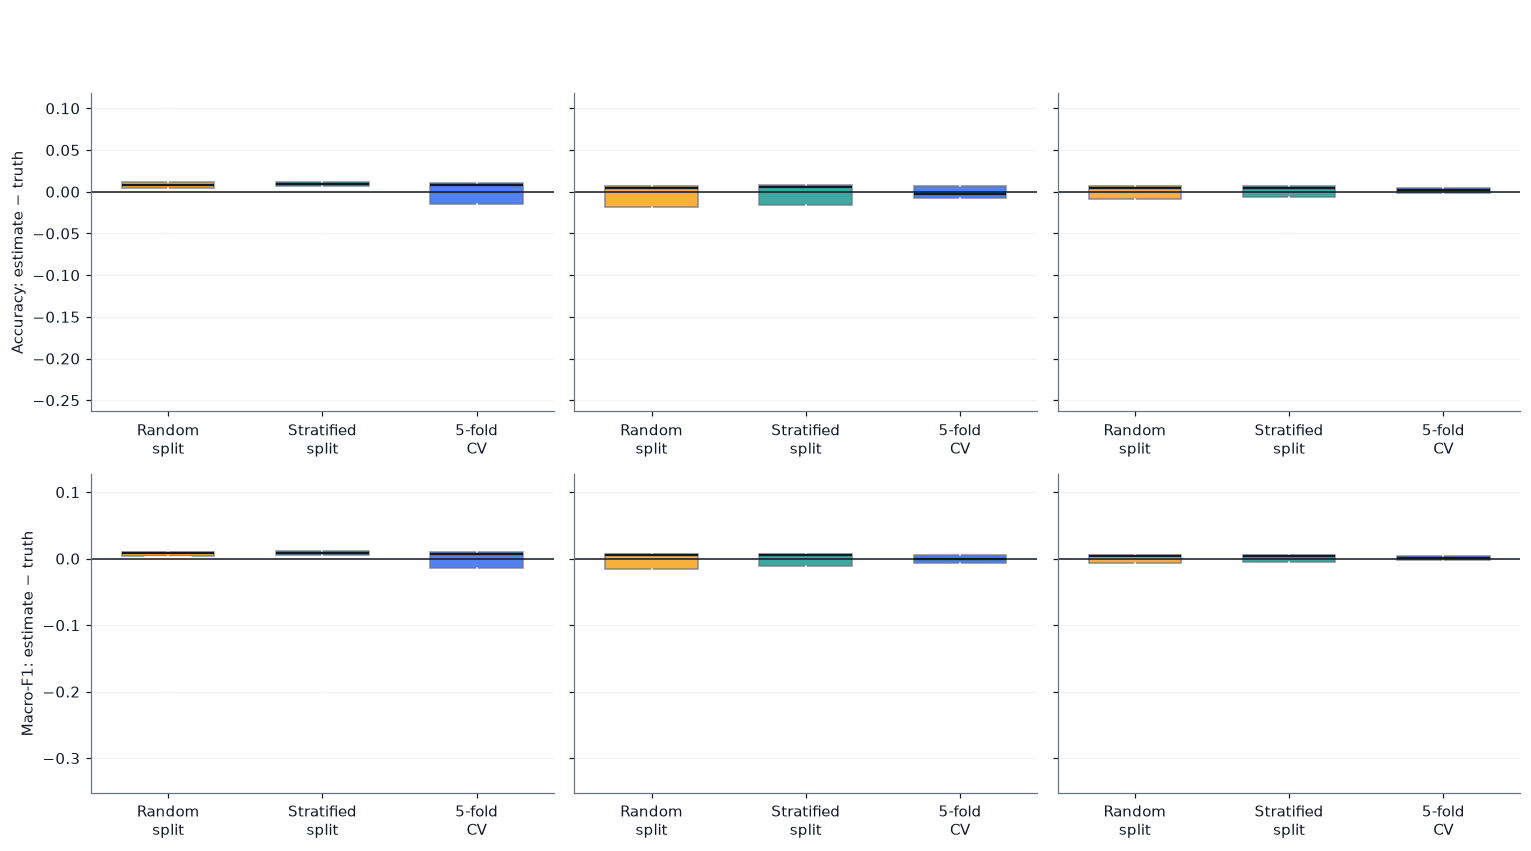

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.6), sharey="row")
proto_colors = [COLORS["orange"], COLORS["teal"], COLORS["blue"]]
for row, (col_name, label) in enumerate([("err_acc", "Accuracy: estimate \u2212 truth"), ("err_f1", "Macro-F1: estimate \u2212 truth")]):
    for ax, n_dev in zip(axes[row], cohort_sizes):
        data = [e1[(e1.n_dev == n_dev) & (e1.protocol == p)][col_name].to_numpy() for p in protocols]
        bp = ax.boxplot(data, patch_artist=True, showfliers=True, widths=0.6, flierprops={"markersize": 3, "alpha": 0.5},
                        medianprops={"color": COLORS["dark"], "linewidth": 1.5})
        for patch, color in zip(bp["boxes"], proto_colors):
            patch.set_facecolor(color); patch.set_alpha(0.8); patch.set_edgecolor(COLORS["gray"])
        ax.axhline(0, color=COLORS["dark"], linewidth=1)
        ax.set_xticks([1, 2, 3]); ax.set_xticklabels(["Random\nsplit", "Stratified\nsplit", "5-fold\nCV"])
        ax.grid(axis="x", visible=False)
        if row == 0: ax.set_title(f"Cohort of {n_dev} patients")
    axes[row][0].set_ylabel(label)
fig.suptitle(f"Error of three evaluation protocols against the truth ({REPLICATES} cohorts per size)", fontsize=13, fontweight="bold", x=0.01, ha="left", y=1.01)
finish(fig, "09_protocol_errors")

How to read the figure (compare with your own tables):

- **Spread** is the main difference between protocols. A single 70/30 split of a small cohort tests the model on only 12–60 patients, so its estimate scatters widely; 5-fold CV tests every patient once and typically has a visibly **narrower** box. The cost is five fits instead of one.
- **Random versus stratified:** for macro-F1, the random split can leave a rare class with zero or one patient in the test set, which makes the metric erratic; stratification reduces the spread, particularly for the smallest cohort.
- **Bias:** all three protocols train on less data than the final model (70% or 80% of the cohort), so they tend to be slightly **pessimistic**, more so for the smallest cohort. This is the price of honesty: a model trained on all patients usually performs a little better than any of its estimates.
- As the cohort grows, all errors shrink: **the evaluation problem is mostly a small-sample problem**.

Note that this dataset is easy (five very different tissues), so the true accuracy is high even for small cohorts and all errors are small in absolute terms. For harder problems (subtypes, treatment response) the same spreads apply to much lower, more uncertain accuracies.

## 13. Experiment E2 — measuring leakage

Now we compare **correct** cross-validation (feature selection inside each training fold) with **leaky** cross-validation (the same $k = 50$ genes chosen once, using all development patients and their labels), in two situations:

1. **Real labels** — the genes really carry information.
2. **Permuted labels** — the cancer-type labels are randomly shuffled across *all* 801 patients, so expression and labels are independent. The true accuracy of *any* model is then at chance level. Any CV estimate above chance is pure leakage.

In [23]:
rng_perm = np.random.default_rng(SEED)
y_permuted = rng_perm.permutation(y_all)                                  # labels independent of the expression data

def leakage_replicate(n_dev, seed, labels, k=50, lam=10.0):
    dev, hold = draw_cohort(n_dev, seed, labels)
    Xd, yd, Xh, yh = X_all[dev], labels[dev], X_all[hold], labels[hold]
    truth = metrics_from_scores(fit_scores(Xd, yd, Xh, N_CLASSES, k, lam), yh)["accuracy"]
    correct = np.mean(cv_predictions(Xd, yd, 5, seed, k, lam, leaky=False) == yd)
    leaky = np.mean(cv_predictions(Xd, yd, 5, seed, k, lam, leaky=True) == yd)
    return truth, correct, leaky

leak_records = []
t0 = time.time()
for label_kind, labels in [("Real labels", y_all), ("Permuted labels", y_permuted)]:
    for n_dev in cohort_sizes:
        for rep in range(REPLICATES):
            truth, correct, leaky = leakage_replicate(n_dev, 77_000 * n_dev + rep, labels)
            leak_records.append({"labels": label_kind, "n_dev": n_dev, "truth": truth, "correct CV": correct, "leaky CV": leaky})
e2 = pd.DataFrame(leak_records)
print(f"Done in {time.time() - t0:.0f} s")

table_e2 = (e2.groupby(["labels", "n_dev"]).agg(**{"true accuracy": ("truth", "mean"), "correct CV": ("correct CV", "mean"), "leaky CV": ("leaky CV", "mean")}))
table_e2["leakage bias (leaky \u2212 truth)"] = table_e2["leaky CV"] - table_e2["true accuracy"]
table_e2["correct-CV bias"] = table_e2["correct CV"] - table_e2["true accuracy"]
display(table_e2.round(3))

Done in 194 s


true accuracy  correct CV  leaky CV  \
labels          n_dev                                        
Permuted labels 40             0.260       0.261     0.750   
                100            0.259       0.249     0.545   
                200            0.268       0.267     0.465   
Real labels     40             0.989       0.991     1.000   
                100            0.994       0.992     0.996   
                200            0.995       0.994     0.996   

                       leakage bias (leaky − truth)  correct-CV bias  
labels          n_dev                                                 
Permuted labels 40                            0.491            0.001  
                100                           0.286           -0.010  
                200                           0.197           -0.000  
Real labels     40                            0.010            0.002  
                100                           0.003           -0.001  
                200                           0.001           -0.001

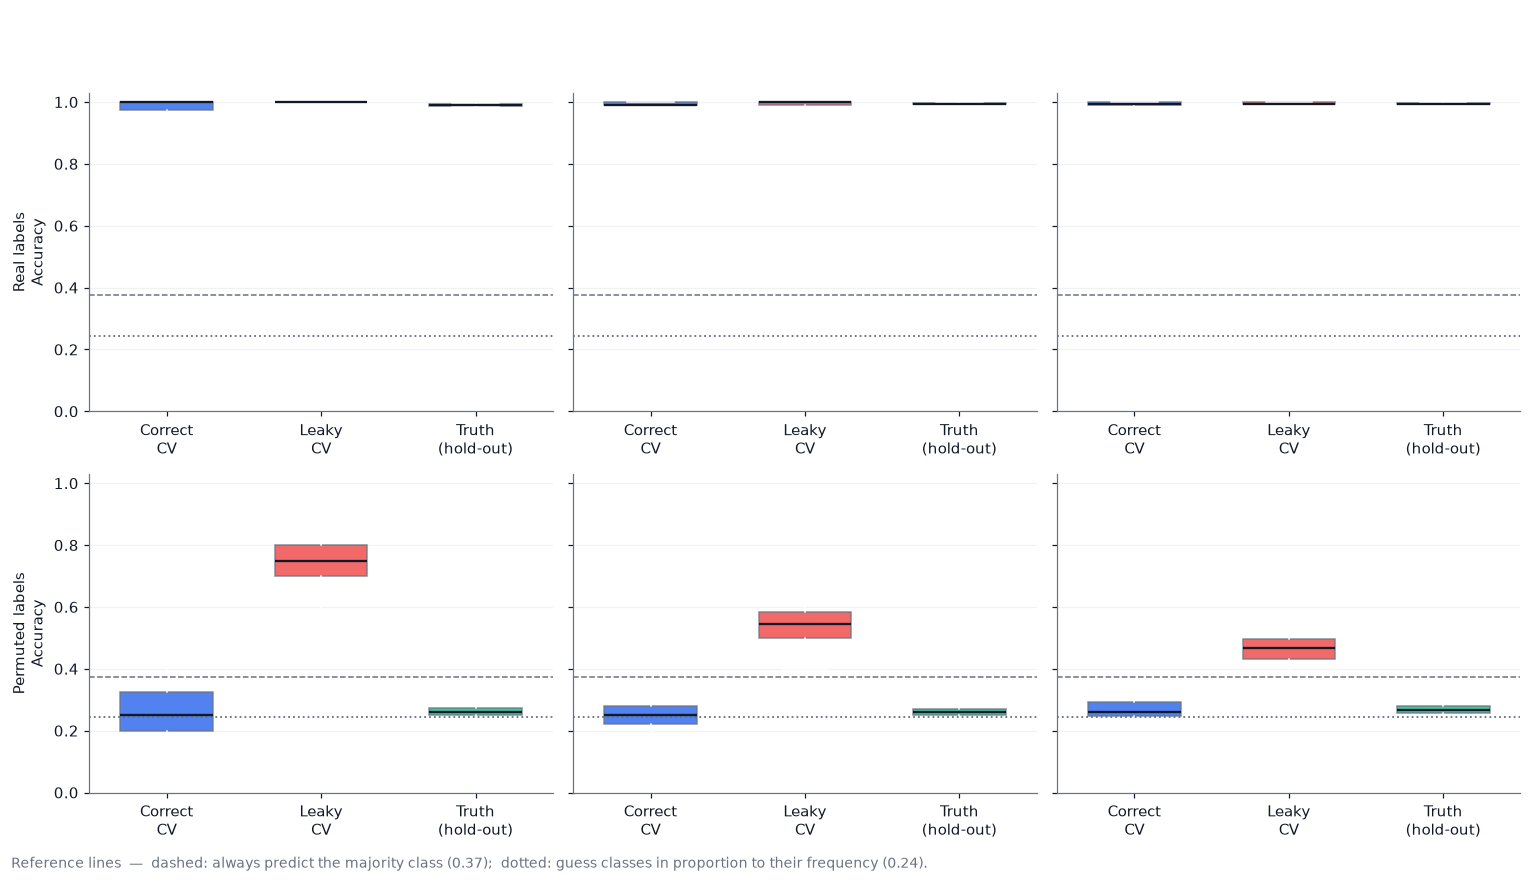

In [24]:
class_share = np.bincount(y_all) / len(y_all)
chance_majority = class_share.max()                                          # always predict the majority class
chance_proportional = float(np.sum(class_share ** 2))                        # guess classes in proportion to their frequency
fig, axes = plt.subplots(2, 3, figsize=(14, 7.6), sharey="row")
for row, label_kind in enumerate(["Real labels", "Permuted labels"]):
    for ax, n_dev in zip(axes[row], cohort_sizes):
        sub = e2[(e2.labels == label_kind) & (e2.n_dev == n_dev)]
        data = [sub["correct CV"].to_numpy(), sub["leaky CV"].to_numpy(), sub["truth"].to_numpy()]
        bp = ax.boxplot(data, patch_artist=True, widths=0.6, flierprops={"markersize": 3, "alpha": 0.5}, medianprops={"color": COLORS["dark"], "linewidth": 1.5})
        for patch, color in zip(bp["boxes"], [COLORS["blue"], COLORS["red"], COLORS["green"]]):
            patch.set_facecolor(color); patch.set_alpha(0.8); patch.set_edgecolor(COLORS["gray"])
        ax.axhline(chance_majority, color=COLORS["gray"], linestyle="--", linewidth=1)
        ax.axhline(chance_proportional, color=COLORS["gray"], linestyle=":", linewidth=1.2)
        ax.set_xticks([1, 2, 3]); ax.set_xticklabels(["Correct\nCV", "Leaky\nCV", "Truth\n(hold-out)"]); ax.grid(axis="x", visible=False)
        ax.set_ylim(0, 1.03)
        if row == 0: ax.set_title(f"Cohort of {n_dev} patients")
    axes[row][0].set_ylabel(f"{label_kind}\nAccuracy")
fig.text(0.01, -0.015, f"Reference lines  \u2014  dashed: always predict the majority class ({chance_majority:.2f});  dotted: guess classes in proportion to their frequency ({chance_proportional:.2f}).",
         fontsize=9, color=COLORS["gray"])
fig.suptitle("Leaky feature selection looks excellent even when the labels carry no information", fontsize=13, fontweight="bold", x=0.01, ha="left", y=1.01)
finish(fig, "10_leakage_experiment")

Look first at the **bottom row** (permuted labels): the truth sits at the no-skill level at every cohort size (about 25%, the accuracy of guessing classes in proportion to their frequency — the dotted line), the **correct** CV estimates scatter around it, while the **leaky** CV reports a clearly higher accuracy — the smaller the cohort, the more spectacular. This is Section 6.1 in action on real data: with 20,531 genes and a few dozen patients, some genes always correlate with any labelling.

In the **top row** (real labels) the genes carry real information, and the leaky estimate is only mildly optimistic here because the signal is strong: do not conclude that leakage is harmless when the signal is strong. With a weaker signal (a subtle subtype, a noisy phenotype), the leakage bias is *much* larger relative to the truth, and the two effects cannot be separated by looking at the leaky number alone.

### 13.1 A permutation test as a sanity check

Is the cross-validated accuracy of one development cohort better than chance? The permutation test answers this by repeating **the whole procedure** on shuffled labels. We run it for the correct pipeline and, for contrast, for the leaky one.

Done in 27 s
Observed CV accuracy (n = 100): correct pipeline 0.970, leaky pipeline 1.000
Permutation p-values with 200 permutations: correct 0.0050, leaky 0.0050  (smallest possible: 0.0050)


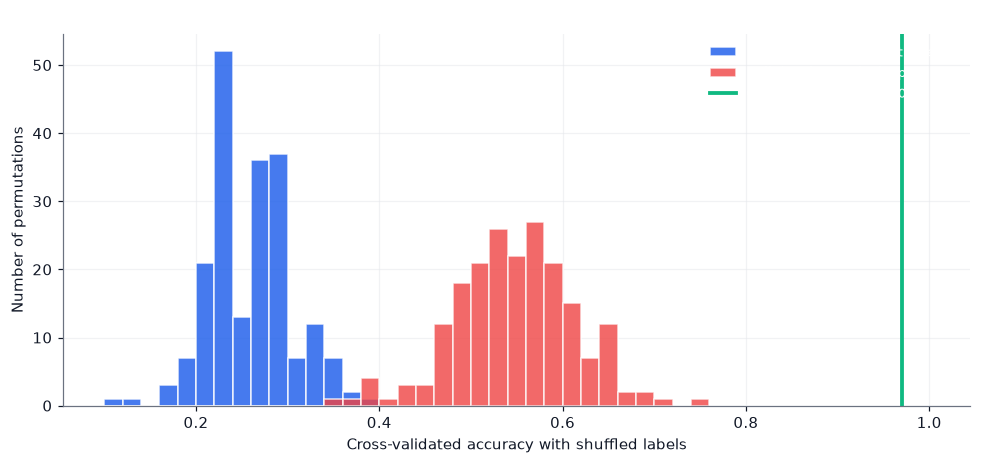

In [25]:
dev_idx, _ = draw_cohort(100, 123, y_all)
Xd, yd = X_all[dev_idx], y_all[dev_idx]
observed_correct = np.mean(cv_predictions(Xd, yd, 5, 0, leaky=False) == yd)
observed_leaky = np.mean(cv_predictions(Xd, yd, 5, 0, leaky=True) == yd)

rng_p = np.random.default_rng(9)
null_correct, null_leaky = [], []
t0 = time.time()
for b in range(N_PERMUTATIONS):
    y_shuffled = rng_p.permutation(yd)
    null_correct.append(np.mean(cv_predictions(Xd, y_shuffled, 5, b, leaky=False) == y_shuffled))
    null_leaky.append(np.mean(cv_predictions(Xd, y_shuffled, 5, b, leaky=True) == y_shuffled))
null_correct, null_leaky = np.array(null_correct), np.array(null_leaky)
p_correct = (1 + np.sum(null_correct >= observed_correct)) / (1 + N_PERMUTATIONS)
p_leaky = (1 + np.sum(null_leaky >= observed_leaky)) / (1 + N_PERMUTATIONS)
print(f"Done in {time.time() - t0:.0f} s")
print(f"Observed CV accuracy (n = {len(yd)}): correct pipeline {observed_correct:.3f}, leaky pipeline {observed_leaky:.3f}")
print(f"Permutation p-values with {N_PERMUTATIONS} permutations: correct {p_correct:.4f}, leaky {p_leaky:.4f}  (smallest possible: {1 / (1 + N_PERMUTATIONS):.4f})")

fig, ax = plt.subplots(figsize=(9, 4.3))
bins = np.linspace(0.1, 1.0, 46)
ax.hist(null_correct, bins=bins, color=COLORS["blue"], alpha=0.85, edgecolor="white", label="Null distribution, correct pipeline")
ax.hist(null_leaky, bins=bins, color=COLORS["red"], alpha=0.8, edgecolor="white", label="Null distribution, leaky pipeline")
ax.axvline(observed_correct, color=COLORS["green"], linewidth=2.5, label=f"Observed (real labels): {observed_correct:.2f}")
ax.set_xlabel("Cross-validated accuracy with shuffled labels"); ax.set_ylabel("Number of permutations")
ax.set_title("The null distribution of a leaky pipeline is shifted upwards"); ax.legend(loc="upper right", fontsize=8.5)
finish(fig, "11_permutation_test")

The null distribution of the **correct** pipeline is centred near chance, so a real-label accuracy far to its right gives a trustworthy small $p$-value. The null distribution of the **leaky** pipeline is shifted upwards: a leaky procedure inflates both the observed score *and* the null scores, which is another reason why leakage is hard to detect from the outside.

## 14. Experiment E3 — a rare class: COAD versus the rest

A realistic diagnostic question is binary and imbalanced: *is this tumour a colon adenocarcinoma (COAD)?* COAD makes up only **9.7%** of the patients. We want a cheap assay, so the model may use only a **panel of 10 genes**. To make the problem informative (not trivially separable), the panel is a **random** sample of 10 genes from the 5,000 genes with the highest variance in the *training* set — a stand-in for a panel designed without prior knowledge.

Design: stratified **60/20/20** split into training, validation, and test sets. The validation set is used for early stopping and for choosing the decision threshold; the **test set is used once**, at the end of this section.

In [26]:
y_bin = (y_all == COAD).astype(int)
tr_b, va_b, te_b = stratified_split_indices(y_all, 0.2, 0.2, seed=SEED)
print("Positives (COAD) in train / validation / test:", int(y_bin[tr_b].sum()), "/", int(y_bin[va_b].sum()), "/", int(y_bin[te_b].sum()),
      "| sizes:", len(tr_b), "/", len(va_b), "/", len(te_b))

K_BINARY = 10
variance_train = X_all[tr_b].var(axis=0)
pool = np.argsort(-variance_train)[:5000]
panel = np.random.default_rng(SEED).choice(pool, size=K_BINARY, replace=False)
Xb = {name: X_all[idx][:, panel].astype("float32") for name, idx in (("train", tr_b), ("val", va_b), ("test", te_b))}
yb = {"train": y_bin[tr_b], "val": y_bin[va_b], "test": y_bin[te_b]}
print("Panel genes (column indices):", np.sort(panel).tolist())

Positives (COAD) in train / validation / test: 46 / 16 / 16 | sizes: 481 / 160 / 160
Panel genes (column indices): [632, 2550, 9178, 13678, 13939, 15435, 16235, 17530, 17583, 18974]


### 14.1 Three models

1. **Ridge classifier** (NumPy, Section 6.2) — produces a *score*, not a probability.
2. **MLP** with one hidden layer of 32 units, dropout 0.3, L2 $10^{-3}$, sigmoid output, binary cross-entropy, early stopping on the validation loss.
3. **MLP with class weights** (positive samples weighted by $N/(2 n_{+})$, negatives by $N/(2 n_{-})$), a common remedy for imbalance (Notebook 06).

We evaluate **ranking** (ROC, PR) for all three, and **calibration** for the two networks.

In [27]:
def build_mlp_binary(X_adapt, hidden=32, dropout=0.3, l2=1e-3, name="mlp_binary"):
    normalization = keras.layers.Normalization(axis=-1, name="normalize_features")
    normalization.adapt(X_adapt)
    return keras.Sequential([
        keras.layers.Input(shape=(X_adapt.shape[1],), name="features"), normalization,
        keras.layers.Dense(hidden, activation="relu", kernel_regularizer=keras.regularizers.L2(l2), name="hidden"),
        keras.layers.Dropout(dropout, name="dropout"),
        keras.layers.Dense(1, activation="sigmoid", name="probability"),
    ], name=name)

def train_mlp_binary(Xtr, ytr, Xva=None, yva=None, class_weight=None, epochs=200, seed=SEED, patience=20):
    keras.utils.set_random_seed(seed)
    model = build_mlp_binary(Xtr)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    callbacks, validation = [], None
    if Xva is not None:
        callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)]
        validation = (Xva, yva)
    model.fit(Xtr, ytr, validation_data=validation, epochs=epochs, batch_size=32, class_weight=class_weight, callbacks=callbacks, verbose=0)
    return model

n_pos, n_neg = int(yb["train"].sum()), int((1 - yb["train"]).sum())
balanced_weights = {0: len(yb["train"]) / (2 * n_neg), 1: len(yb["train"]) / (2 * n_pos)}
print("Class weights:", {k: round(v, 2) for k, v in balanced_weights.items()})

mlp_plain = train_mlp_binary(Xb["train"], yb["train"], Xb["val"], yb["val"])
mlp_weighted = train_mlp_binary(Xb["train"], yb["train"], Xb["val"], yb["val"], class_weight=balanced_weights)

def ridge_binary_score(Xtr, ytr, Xte, lam=10.0):
    s = ridge_dual_scores(Xtr, ytr, Xte, 2, lam)
    return s[:, 1] - s[:, 0]

scores = {
    "Ridge (score)": {part: ridge_binary_score(Xb["train"], yb["train"], Xb[part]) for part in ("val", "test")},
    "MLP": {part: mlp_plain.predict(Xb[part], verbose=0).ravel() for part in ("val", "test")},
    "MLP + class weights": {part: mlp_weighted.predict(Xb[part], verbose=0).ravel() for part in ("val", "test")},
}
model_colors = {"Ridge (score)": COLORS["purple"], "MLP": COLORS["blue"], "MLP + class weights": COLORS["orange"]}

Class weights: {0: 0.55, 1: 5.23}


In [28]:
def bootstrap_ci(metric_fn, y_true, score, n_boot=N_BOOT, seed=0):
    """Percentile bootstrap interval of metric_fn(y, score); resamples without both classes are skipped."""
    r = np.random.default_rng(seed); n = len(y_true); values = []
    for _ in range(n_boot):
        idx = r.integers(0, n, size=n)
        if y_true[idx].min() == y_true[idx].max():
            continue
        values.append(metric_fn(y_true[idx], score[idx]))
    return np.percentile(values, [2.5, 97.5])

rows = []
for name, sc in scores.items():
    auc, ap = auc_rank(yb["test"], sc["test"]), average_precision(yb["test"], sc["test"])
    auc_lo, auc_hi = bootstrap_ci(auc_rank, yb["test"], sc["test"])
    ap_lo, ap_hi = bootstrap_ci(average_precision, yb["test"], sc["test"])
    rows.append({"model": name, "AUC": f"{auc:.3f} [{auc_lo:.3f}, {auc_hi:.3f}]", "average precision": f"{ap:.3f} [{ap_lo:.3f}, {ap_hi:.3f}]"})
display(pd.DataFrame(rows).set_index("model"))
print(f"Chance level: AUC = 0.5, average precision = prevalence = {yb['test'].mean():.3f}")

,AUC,average precision
model,,
Ridge (score),"0.970 [0.942, 0.991]","0.768 [0.539, 0.934]"
MLP,"0.988 [0.971, 1.000]","0.837 [0.629, 1.000]"
MLP + class weights,"0.987 [0.969, 0.999]","0.822 [0.620, 0.994]"


Chance level: AUC = 0.5, average precision = prevalence = 0.100


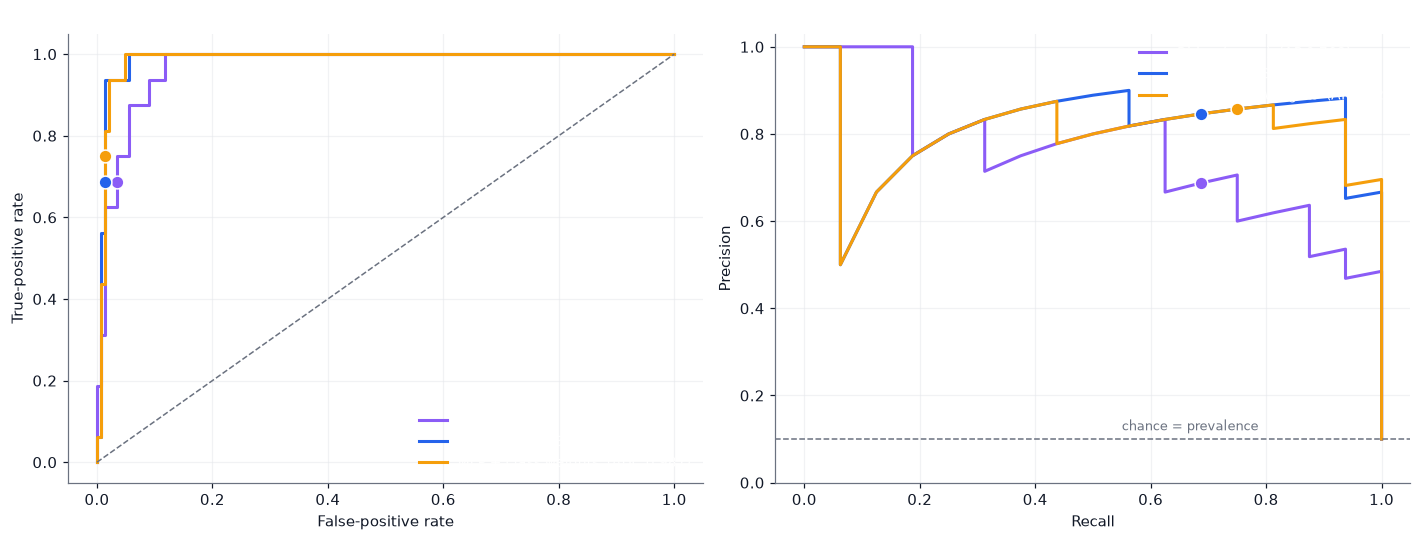

In [29]:
# Operating points: the threshold is chosen on the VALIDATION set (maximum F1) and applied to the TEST set.
def best_f1_threshold(y_true, score):
    candidates = np.unique(score)
    f1s = [binary_metrics(y_true, score >= t)["F1"] for t in candidates]
    f1s = np.nan_to_num(f1s, nan=-1)
    return float(candidates[int(np.argmax(f1s))])

thresholds = {name: best_f1_threshold(yb["val"], sc["val"]) for name, sc in scores.items()}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.0))
for name, sc in scores.items():
    color = model_colors[name]
    fpr, tpr, _ = roc_curve_np(yb["test"], sc["test"]); prec, rec, _ = pr_curve_np(yb["test"], sc["test"])
    axes[0].plot(fpr, tpr, color=color, label=f"{name}  (AUC {auc_rank(yb['test'], sc['test']):.3f})")
    axes[1].plot(rec, prec, color=color, label=f"{name}  (AP {average_precision(yb['test'], sc['test']):.3f})")
    m = binary_metrics(yb["test"], sc["test"] >= thresholds[name])
    axes[0].scatter([1 - m["specificity"]], [m["sensitivity"]], color=color, s=70, edgecolor="white", zorder=5)
    axes[1].scatter([m["sensitivity"]], [m["PPV"]], color=color, s=70, edgecolor="white", zorder=5)
axes[0].plot([0, 1], [0, 1], color=COLORS["gray"], linestyle="--", linewidth=1)
axes[1].axhline(yb["test"].mean(), color=COLORS["gray"], linestyle="--", linewidth=1)
axes[1].annotate("chance = prevalence", (0.55, yb["test"].mean() + 0.02), fontsize=8.5, color=COLORS["gray"])
axes[0].set_xlabel("False-positive rate"); axes[0].set_ylabel("True-positive rate"); axes[0].set_title("ROC curves on the test set (dots: threshold chosen on validation)"); axes[0].legend(loc="lower right")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision\u2013recall curves on the test set"); axes[1].legend(loc="upper right"); axes[1].set_ylim(0, 1.03)
finish(fig, "12_roc_pr_coad")

In [30]:
rows = []
for name, sc in scores.items():
    m = binary_metrics(yb["test"], sc["test"] >= thresholds[name])
    s_lo, s_hi = wilson_interval(m["TP"], m["TP"] + m["FN"]); sp_lo, sp_hi = wilson_interval(m["TN"], m["TN"] + m["FP"])
    p_lo, p_hi = wilson_interval(m["TP"], m["TP"] + m["FP"]) if (m["TP"] + m["FP"]) > 0 else (float("nan"), float("nan"))
    rows.append({"model": name, "threshold": round(thresholds[name], 3), "TP": m["TP"], "FP": m["FP"], "FN": m["FN"], "TN": m["TN"],
                 "sensitivity": f"{m['sensitivity']:.2f} [{s_lo:.2f}, {s_hi:.2f}]", "specificity": f"{m['specificity']:.2f} [{sp_lo:.2f}, {sp_hi:.2f}]",
                 "PPV": f"{m['PPV']:.2f} [{p_lo:.2f}, {p_hi:.2f}]", "F1": round(m["F1"], 3), "MCC": round(m["MCC"], 3)})
display(pd.DataFrame(rows).set_index("model"))
print("Intervals are 95% Wilson intervals. The sensitivity is based on", int(yb["test"].sum()), "positive test patients only.")

,threshold,TP,FP,FN,TN,sensitivity,specificity,PPV,F1,MCC
model,,,,,,,,,,
Ridge (score),-0.363,11,5,5,139,"0.69 [0.44, 0.86]","0.97 [0.92, 0.99]","0.69 [0.44, 0.86]",0.688,0.653
MLP,0.567,11,2,5,142,"0.69 [0.44, 0.86]","0.99 [0.95, 1.00]","0.85 [0.58, 0.96]",0.759,0.740
MLP + class weights,0.887,12,2,4,142,"0.75 [0.51, 0.90]","0.99 [0.95, 1.00]","0.86 [0.60, 0.96]",0.800,0.782


Intervals are 95% Wilson intervals. The sensitivity is based on 16 positive test patients only.


Observe three things (compare with your own numbers):

1. The three models may have **similar AUCs** whose bootstrap intervals overlap broadly: with only about 16 positive test patients, the data cannot rank them with confidence. The width of the intervals is the honest message.
2. The **operating points** (dots) show how the threshold, not the model, determines the trade-off between sensitivity, specificity, and PPV. The same model can be made more sensitive (more false alarms) or more precise (more missed cases).
3. The **intervals for sensitivity and PPV are wide** because they rely on small numbers (positives for the sensitivity, predicted positives for the PPV).

### 14.2 Calibration: class weights improve recall but distort probabilities

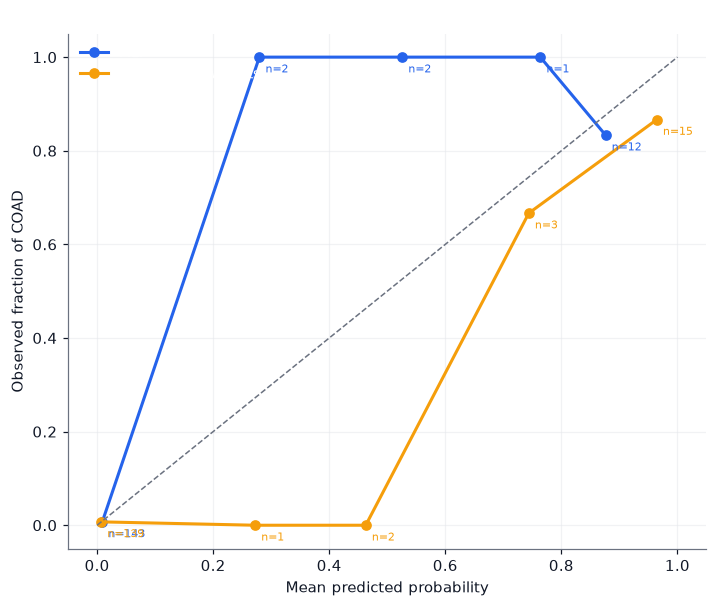

,Brier score,ECE (5 bins),mean predicted probability
model,,,
MLP,0.0268,0.0213,0.088
MLP + class weights,0.0255,0.0183,0.118


Observed prevalence in the test set: 0.100


In [31]:
fig, ax = plt.subplots(figsize=(6.6, 5.6))
rows = []
for name in ["MLP", "MLP + class weights"]:
    p = scores[name]["test"]
    rel = reliability_bins(yb["test"], p, n_bins=5)
    ax.plot(rel[:, 0], rel[:, 1], "o-", color=model_colors[name], label=name)
    for x_, y_, n_ in rel:
        ax.annotate(f"n={int(n_)}", (x_, y_), textcoords="offset points", xytext=(4, -10), fontsize=7.5, color=model_colors[name])
    rows.append({"model": name, "Brier score": round(brier_score(yb["test"], p), 4), "ECE (5 bins)": round(expected_calibration_error(yb["test"], p, 5), 4),
                 "mean predicted probability": round(float(p.mean()), 3)})
ax.plot([0, 1], [0, 1], color=COLORS["gray"], linestyle="--", linewidth=1)
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed fraction of COAD"); ax.set_title("Reliability diagram on the test set (5 bins)"); ax.legend(loc="upper left")
finish(fig, "13_reliability_coad")
display(pd.DataFrame(rows).set_index("model"))
print(f"Observed prevalence in the test set: {yb['test'].mean():.3f}")

With class weights, the loss is effectively computed on a *rebalanced* population in which positives are as frequent as negatives, so the predicted probabilities are **inflated relative to the true prevalence**: look at the mean predicted probability against the observed prevalence, and at the reliability curve lying above the diagonal at low probabilities. The ranking (AUC) can be just as good, but the probabilities can no longer be read as risks, and the cost-based threshold of Section 9.2 would be wrong. If calibrated probabilities are needed, train without weights, or **recalibrate** afterwards (for example, with a logistic regression on the validation scores — Platt scaling). With only 160 test patients and 16 positives, each reliability bin holds few positives, so this plot is itself noisy.

## 15. Experiment E4 — comparing models with repeated cross-validation

Which model is better: the ridge classifier, a nearest-centroid classifier, or the MLP? We use the development set (training + validation, 80% of the patients) and the metric **AUC**, with **5-fold stratified CV repeated 3 times** (15 paired folds: all models are evaluated on exactly the same folds). Inside each training fold, standardization is fitted on that fold only; the MLP uses a fixed 100 epochs (no early stopping, since a validation set would have to be carved out of each fold).

In [32]:
dev_b = np.concatenate([tr_b, va_b])
Xdev, ydev = X_all[dev_b][:, panel].astype("float32"), y_bin[dev_b]

def centroid_score(Xtr, ytr, Xte):
    mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0) + 1e-8
    Xt, Xe = (Xtr - mu) / sd, (Xte - mu) / sd
    m0, m1 = Xt[ytr == 0].mean(axis=0), Xt[ytr == 1].mean(axis=0)
    return ((Xe - m0) ** 2).sum(axis=1) - ((Xe - m1) ** 2).sum(axis=1)             # larger = closer to the positive centroid

def mlp_score(Xtr, ytr, Xte, seed=SEED):
    return train_mlp_binary(Xtr, ytr, epochs=100, seed=seed).predict(Xte, verbose=0).ravel()

model_fns = {"Ridge": lambda a, b, c: ridge_binary_score(a, b, c), "Nearest centroid": centroid_score, "MLP": mlp_score}

fold_auc = {name: [] for name in model_fns}
fold_sizes = []
t0 = time.time()
for repeat in range(3):
    for tr, te in stratified_kfold(ydev, 5, seed=100 + repeat):
        fold_sizes.append((len(tr), len(te)))
        for name, fn in model_fns.items():
            fold_auc[name].append(auc_rank(ydev[te], fn(Xdev[tr], ydev[tr], Xdev[te])))
print(f"Done in {time.time() - t0:.0f} s")
n_train_cv, n_test_cv = fold_sizes[0]

rows = []
for name in model_fns:
    a = np.array(fold_auc[name]); rows.append({"model": name, "mean AUC": round(a.mean(), 3), "SD over folds": round(a.std(ddof=1), 3), "min": round(a.min(), 3), "max": round(a.max(), 3)})
display(pd.DataFrame(rows).set_index("model"))

Done in 92 s


,mean AUC,SD over folds,min,max
model,,,,
Ridge,0.954,0.037,0.862,0.993
Nearest centroid,0.946,0.040,0.844,0.994
MLP,0.977,0.025,0.910,0.999


,mean AUC difference,naive t-test p,corrected t-test p,folds where A > B
comparison (A − B),,,,
MLP − Ridge,0.0232,0.0000,0.0126,15/15
MLP − Nearest centroid,0.0310,0.0000,0.0083,15/15
Ridge − Nearest centroid,0.0079,0.0067,0.1679,11/15


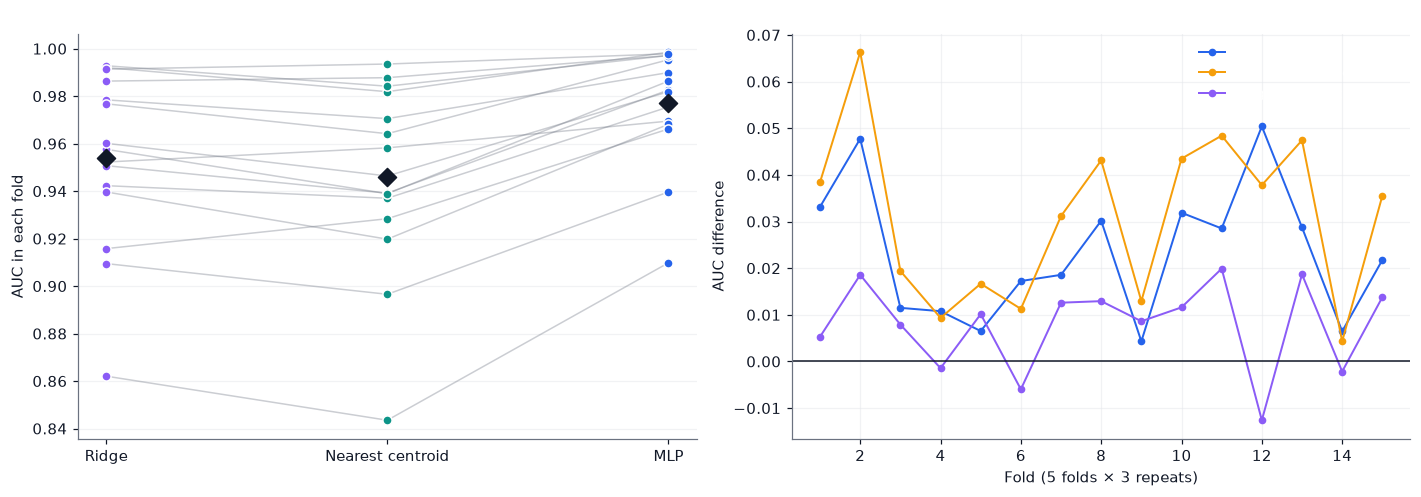

Each fold: 512 training and 129 test patients. The corrected t-test inflates the variance by the factor 1/J + n_test/n_train = 0.319 / 0.067 = 4.8.


In [33]:
pairs = [("MLP", "Ridge"), ("MLP", "Nearest centroid"), ("Ridge", "Nearest centroid")]
rows = []
for a_name, b_name in pairs:
    d = np.array(fold_auc[a_name]) - np.array(fold_auc[b_name])
    t_naive = d.mean() / (d.std(ddof=1) / math.sqrt(len(d)))
    t_corr, p_corr = corrected_resampled_ttest(d, n_train_cv, n_test_cv)
    p_naive = student_t_two_sided_p(t_naive, len(d) - 1)
    rows.append({"comparison (A \u2212 B)": f"{a_name} \u2212 {b_name}", "mean AUC difference": round(d.mean(), 4), "naive t-test p": round(p_naive, 4),
                 "corrected t-test p": round(p_corr, 4), "folds where A > B": f"{int(np.sum(d > 0))}/{len(d)}"})
display(pd.DataFrame(rows).set_index("comparison (A \u2212 B)"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
names_m = list(model_fns); xs = np.arange(len(names_m))
for j in range(len(fold_auc[names_m[0]])):
    axes[0].plot(xs, [fold_auc[n][j] for n in names_m], color=COLORS["gray"], alpha=0.35, linewidth=1)
for x_, n in zip(xs, names_m):
    axes[0].scatter(np.full(len(fold_auc[n]), x_), fold_auc[n], color=model_colors.get(n, COLORS["teal"]) if n != "Ridge" else COLORS["purple"], s=36, zorder=4, edgecolor="white")
    axes[0].scatter([x_], [np.mean(fold_auc[n])], marker="D", color=COLORS["dark"], s=70, zorder=5)
axes[0].set_xticks(xs); axes[0].set_xticklabels(names_m); axes[0].set_ylabel("AUC in each fold"); axes[0].set_title("Paired fold results (lines join the same fold; diamond = mean)")
axes[0].grid(axis="x", visible=False)
for (a_name, b_name), color in zip(pairs, [COLORS["blue"], COLORS["orange"], COLORS["purple"]]):
    d = np.array(fold_auc[a_name]) - np.array(fold_auc[b_name])
    axes[1].plot(np.arange(1, len(d) + 1), d, "o-", color=color, markersize=4, linewidth=1.3, label=f"{a_name} \u2212 {b_name}")
axes[1].axhline(0, color=COLORS["dark"], linewidth=1); axes[1].set_xlabel("Fold (5 folds \u00d7 3 repeats)"); axes[1].set_ylabel("AUC difference")
axes[1].set_title("Paired differences per fold"); axes[1].legend(fontsize=8.5)
finish(fig, "14_cv_model_comparison")
print(f"Each fold: {n_train_cv} training and {n_test_cv} test patients. The corrected t-test inflates the variance by the factor 1/J + n_test/n_train = {1 / len(fold_sizes) + n_test_cv / n_train_cv:.3f} / {1 / len(fold_sizes):.3f} = {(1 / len(fold_sizes) + n_test_cv / n_train_cv) * len(fold_sizes):.1f}.")

Compare the *naive* and the *corrected* $p$-values: the naive test treats the 15 folds as independent and is overconfident; the corrected version accounts for the overlap between training sets and typically gives much larger $p$-values. If a difference is only "significant" under the naive test, treat it as unproven. Also check **how many folds** favour model A: a mean difference carried by a few folds is fragile.

### 15.1 Nested cross-validation: choosing hyperparameters without fooling yourself

For the ridge classifier we also choose a regularization strength $\lambda$ and the number of genes used ($k$ of the 10 panel genes): $5 \times 3 = 15$ configurations. Two ways to report performance:

- **Non-nested (naive):** run CV for each configuration and report the CV score of the **best** one. This is the winner's curse of Section 10.2.
- **Nested:** an **outer** 5-fold CV evaluates the *procedure* "pick the best configuration with an **inner** 3-fold CV on the outer-training data, then train with it". The outer test folds never influence the choice.

In [34]:
grid = [(k, lam) for k in (5, 8, 10) for lam in (0.1, 1.0, 10.0, 100.0, 1000.0)]

def ridge_auc(Xtr, ytr, Xte, yte, k, lam):
    return auc_rank(yte, ridge_binary_score(Xtr[:, :k], ytr, Xte[:, :k], lam))

def cv_grid_scores(X, y, seed, n_splits=5):
    """Mean CV AUC of every configuration of the grid (same folds for all configurations)."""
    folds = list(stratified_kfold(y, n_splits, seed))
    return np.array([np.mean([ridge_auc(X[tr], y[tr], X[te], y[te], k, lam) for tr, te in folds]) for k, lam in grid])

naive_best, nested_scores = [], []
t0 = time.time()
for repeat in range(3):
    naive_best.append(cv_grid_scores(Xdev, ydev, seed=200 + repeat).max())             # best configuration, scored on the same folds
    outer = []
    for tr, te in stratified_kfold(ydev, 5, seed=300 + repeat):
        inner_scores = cv_grid_scores(Xdev[tr], ydev[tr], seed=400 + repeat, n_splits=3)
        k_best, lam_best = grid[int(np.argmax(inner_scores))]
        outer.append(ridge_auc(Xdev[tr], ydev[tr], Xdev[te], ydev[te], k_best, lam_best))
    nested_scores.append(np.mean(outer))
print(f"Done in {time.time() - t0:.0f} s")
print(f"Non-nested: AUC of the best of {len(grid)} configurations = {np.mean(naive_best):.4f}")
print(f"Nested CV : AUC of the whole selection procedure           = {np.mean(nested_scores):.4f}")
print(f"Optimism of the naive report: {np.mean(naive_best) - np.mean(nested_scores):+.4f} AUC")

Done in 9 s
Non-nested: AUC of the best of 15 configurations = 0.9517
Nested CV : AUC of the whole selection procedure           = 0.9553
Optimism of the naive report: -0.0036 AUC


In [35]:
# Hold-out comparison at the thresholds chosen on validation: McNemar's exact test for correctness of predictions.
pred_ridge = scores["Ridge (score)"]["test"] >= thresholds["Ridge (score)"]
pred_mlp = scores["MLP"]["test"] >= thresholds["MLP"]
b_, c_, p_mc = mcnemar_exact(pred_mlp == yb["test"].astype(bool), pred_ridge == yb["test"].astype(bool))
print(f"McNemar (MLP vs Ridge) on {len(yb['test'])} test patients: MLP right & Ridge wrong = {b_}, Ridge right & MLP wrong = {c_}, exact p = {p_mc:.3f}")
print("Only the discordant patients carry information; with few of them, the test has little power.")

McNemar (MLP vs Ridge) on 160 test patients: MLP right & Ridge wrong = 4, Ridge right & MLP wrong = 1, exact p = 0.375
Only the discordant patients carry information; with few of them, the test has little power.


The non-nested number is usually higher than the nested one, although with a small grid and a stable model the difference can be tiny and may even be slightly negative by chance. The gap is an estimate of the **selection optimism**: it grows with the number of configurations tried and shrinks with the sample size. With 15 configurations of a very stable model the gap is small; with hundreds of configurations of a flexible model, as in a typical hyperparameter search, it can be large. **The nested number is the honest one** — it evaluates the procedure that you will actually apply to the final data.

## 16. Scientific interpretation and reporting

### 16.1 What the results mean

- A high accuracy for the **five-tissue** classification says that expression profiles of breast, kidney, lung, prostate, and colon tumours are very different — a known biological fact. It does **not** say that the model could subtype breast cancers, or generalize to RNA-Seq from another platform, another hospital, or biopsies instead of resected tumours.
- The model can only know what the data contain. **TCGA** samples come from specific cohorts and processing pipelines: a different pipeline can create *batch effects* that a model trained here has never seen. Strong performance in cross-validation is **internal validation**; the scientifically stronger statement requires **external validation** on an independent cohort.
- The gene names are anonymized in this version of the dataset (`gene_0` … `gene_20530`), so **no biological interpretation of the selected genes is possible here**. In a real study, one would map the features to gene identifiers, check that the selected genes make biological sense (known markers of the tissues), and use pathway or enrichment analysis.
- A **small panel** can retain a lot of information, but the panel here was random: a designed panel (known markers, or genes selected inside cross-validation) would do much better and could be validated in the lab.

### 16.2 A reporting checklist

| Item | What to state |
|---|---|
| **Data** | source, licence, number of patients and of positives per class, inclusion/exclusion, how related samples (same patient) were handled |
| **Split** | partition sizes, stratification, grouping by patient, random seed, **what was done before the split** |
| **Preprocessing** | every transformation, and that it was fitted on training data only; feature selection inside the training folds |
| **Model selection** | which models and hyperparameters were tried, how many, and on which data (validation or nested CV) |
| **Metric choice** | why this metric for this question; prevalence; threshold and how it was chosen |
| **Uncertainty** | confidence intervals (Wilson for proportions, bootstrap for AUC/F1), number of seeds or folds, paired tests when comparing models |
| **Baselines** | majority class, a simple linear model, previously published methods |
| **Calibration** | reliability diagram or Brier score when probabilities are used |
| **Limitations** | population, platform, time period, class imbalance, possible batch effects; absence of external validation |
| **Code and data** | scripts, versions of all packages, random seeds |

### 16.3 Limitations of this notebook

1. The "pilot cohort" experiment uses patients from one dataset, so the cohort and the hold-out population come from the *same* distribution: it measures sampling variability and leakage, but **not** distribution shift, which usually dominates in practice.
2. The simulations use one simple model (ANOVA + ridge). The size of the leakage bias and of the protocol errors depends on the model, the signal strength, and $p/n$.
3. TCGA tumours may include several samples per patient or related samples; we had no patient identifiers, so a grouped split was not possible.
4. In the COAD experiment, the test set holds about 16 positive patients, so every number about the rare class carries a wide interval.

## 17. What did we learn?

1. An evaluation **estimates** a true performance; the estimate has bias and variance. For accuracy, $\operatorname{Var}(\hat{A}) = A(1-A)/n$: intervals shrink like $1/\sqrt{n}$, and for rare classes the relevant $n$ is the **number of patients in that class**. Use Wilson or Clopper–Pearson intervals, not Wald.
2. **Stratified** splitting removes the hypergeometric variability of class counts.
3. **Leakage**: selecting features on all data when $p \gg n$ exploits $\mathbb{E}[\max_j |r_j|] \approx \sqrt{2\ln p/n}$. Every learned step (scaling, selection, hyperparameters, thresholds) must live **inside** the training data of each fold. We saw leakage turn pure noise into a high accuracy.
4. Binary metrics have different meanings; **PPV depends on prevalence** through Bayes' theorem, and accuracy can be useless for rare classes (the accuracy paradox).
5. **AUC** $= \mathbb{P}(S^{+} > S^{-})$ (Mann–Whitney); it is invariant to monotone score transformations and to prevalence. **PR curves** and average precision expose the cost of imbalance (chance level = prevalence).
6. Thresholds come from validation data or costs: $p^{*} = c_{FP}/(c_{FP}+c_{FN})$ for calibrated probabilities. **Calibration** is separate from ranking; class weights improve recall but distort probabilities.
7. **Cross-validation** is more efficient than one split; repeated CV reduces variance; the **winner's curse** inflates the best of many models by about $\sigma\sqrt{2\ln M}$; **nested CV** evaluates the whole selection procedure.
8. Compare models with **paired** procedures (McNemar, corrected resampled $t$-test); a **permutation test** answers "better than chance?" — but only for a leak-free pipeline.
9. Report intervals, baselines, limitations, and the exact protocol. Internal validation is not external validation.

### Key terms

| Term | Meaning |
|---|---|
| Generalization error | Expected loss on new data from the target population |
| Data leakage | Information from evaluation data influencing the model or its selection |
| Stratified / grouped split | Preserve class proportions / keep related samples together |
| Sensitivity, specificity | Fraction of positives / negatives correctly identified |
| PPV, NPV | Probability of being truly positive/negative given a positive/negative prediction |
| ROC curve, AUC | TPR against FPR over all thresholds; $\mathbb{P}(S^{+} > S^{-})$ |
| Precision–recall curve, AP | Precision against recall; chance level is the prevalence |
| Calibration, Brier score, ECE | Agreement between predicted probabilities and frequencies |
| Nested cross-validation | An outer CV evaluating a procedure that selects its configuration with an inner CV |
| Winner's curse | Optimism of the best of many noisy estimates |
| McNemar test | Paired test on discordant predictions of two models |
| Permutation test | Null distribution built by shuffling labels and repeating the whole procedure |
| External validation | Evaluation on an independent cohort |

## 18. Exercises

### A. Mathematics

1. A test set has 50 patients and 47 correct predictions. Compute the Wald, Wilson, and Clopper–Pearson 95% intervals by hand (or with the functions of Section 4). Which would you report?
2. Derive $\operatorname{Var}[\#\text{pos}]$ for the hypergeometric distribution from the Bernoulli indicators of sampling without replacement (use $\operatorname{Cov}(I_i, I_j) = -\tfrac{M(N-M)}{N^2(N-1)}$).
3. A test has sensitivity 0.95 and specificity 0.95. Compute the PPV for prevalences 0.5, 0.1, 0.01, and 0.001. At which prevalence does the PPV fall below 0.5?
4. Prove that $F_1$ ignores true negatives, and give two classifiers with the same $F_1$ but very different specificity.
5. Prove the identity $\text{AUC} = U/(n_+n_-)$ with $U = R_+ - n_+(n_++1)/2$, where $R_+$ is the sum of the ranks of the positive scores.
6. Show that applying a strictly increasing function to a score does not change the ROC curve. Show that the expected AP of a random scorer equals the prevalence (approximately, for large samples).
7. Derive the cost-optimal threshold $p^{*}$ when the cost of a *correct* positive decision is also nonzero: $c_{TP}$ and $c_{TN}$ (hint: compare expected costs and note that only the *differences* $c_{FP}-c_{TN}$ and $c_{FN}-c_{TP}$ matter).
8. For $M$ independent standard normal variables, derive that $\mathbb{E}[\max_m |Z_m|] \approx \sqrt{2\ln M}$ (hint: solve $M\,\mathbb{P}(|Z| > x) \approx 1$ using the tail bound $\mathbb{P}(|Z|>x) \lesssim e^{-x^2/2}$).
9. Explain why the corrected resampled $t$-test multiplies $1/J$ by $1 + J\,n_{\text{test}}/n_{\text{train}}$, and compute this factor for 10-fold CV with 10 repeats.

### B. Programming

1. Repeat the leakage experiment of Section 13 for $k = 5, 20, 100, 500$ selected genes. How does the leakage bias depend on $k$ and on the cohort size?
2. Add a **third** protocol to Experiment E1: the **0.632 bootstrap**, or a **leave-one-out** estimate. Compare its bias and variance with 5-fold CV.
3. Replace the ANOVA selection by a selection that uses **only the 1000 genes with the highest variance computed on all patients** (including the hold-out ones). Is this leaky? Measure the effect with the pilot-cohort experiment.
4. Implement **Platt scaling** (a logistic regression on the validation scores) and recalibrate the class-weighted MLP of Section 14. Compare reliability diagrams and Brier scores before and after.
5. In Section 15, replace AUC by average precision as the metric. Does the ranking of the three models change?
6. Implement **grouped** cross-validation: pretend that every 4 consecutive patients come from the same donor and make sure that they are never split across training and test folds. Compare the CV accuracy with and without grouping after you add *correlated* samples (duplicate each patient with a little noise).
7. Compute the **Hanley–McNeil** or the **DeLong** confidence interval of the AUC and compare with the bootstrap interval of Section 14.
8. Extend the permutation test of Section 13.1 to the AUC of the COAD task. Is the AUC of the MLP significantly above 0.5 on the development set?

### C. Research thinking

1. A paper reports 99% cross-validated accuracy for a tumour classifier on 60 patients, selecting the 100 "best" genes on the whole dataset first. Describe at least three ways to check whether the result is trustworthy, and what additional information you would ask the authors for.
2. For a screening test for a disease with a prevalence of 0.5%, which metrics would you report and which would you avoid? How would you choose the threshold?
3. You have 5 hospitals' data. Explain how **leave-one-hospital-out** cross-validation differs from ordinary CV, what it measures, and why it is usually more pessimistic.
4. Design a study to decide between two models whose cross-validated AUCs are 0.91 and 0.93 on 150 patients. How many patients would you need to detect a difference of 0.02 with reasonable power? (Think about the variance of paired differences.)

## 19. Further exploration and references

### Datasets

- Fiorini, S. (2016). *Gene expression cancer RNA-Seq* [Dataset]. UCI Machine Learning Repository. <https://doi.org/10.24432/C5R88H> (CC BY 4.0).
- Weinstein, J. N., *et al.* (2013). The Cancer Genome Atlas Pan-Cancer analysis project. *Nature Genetics*, 45(10), 1113–1120.

### Methods

- Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association*, 22, 209–212.
- Clopper, C. J. and Pearson, E. S. (1934). The use of confidence or fiducial limits illustrated in the case of the binomial. *Biometrika*, 26, 404–413.
- Ambroise, C. and McLachlan, G. J. (2002). Selection bias in gene extraction on the basis of microarray gene-expression data. *Proceedings of the National Academy of Sciences*, 99(10), 6562–6566.
- Varma, S. and Simon, R. (2006). Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics*, 7, 91.
- Hanley, J. A. and McNeil, B. J. (1982). The meaning and use of the area under a receiver operating characteristic (ROC) curve. *Radiology*, 143, 29–36.
- Saito, T. and Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE*, 10(3), e0118432.
- Nadeau, C. and Bengio, Y. (2003). Inference for the generalization error. *Machine Learning*, 52, 239–281.
- Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10, 1895–1923.
- Efron, B. and Tibshirani, R. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.
- Guo, C., Pleiss, G., Sun, Y., and Weinberger, K. Q. (2017). On calibration of modern neural networks. *ICML*.
- Niculescu-Mizil, A. and Caruana, R. (2005). Predicting good probabilities with supervised learning. *ICML*.
- Cawley, G. C. and Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *Journal of Machine Learning Research*, 11, 2079–2107.

### Documentation

- Keras: [metrics](https://keras.io/api/metrics/) (including AUC, Precision, Recall), [losses](https://keras.io/api/losses/), [callbacks](https://keras.io/api/callbacks/).

### Suggested reading

- Goodfellow, Bengio, and Courville — *Deep Learning*: chapter 5 (capacity, validation, estimators, cross-validation) and chapter 11 (practical methodology).
- Hastie, Tibshirani, and Friedman — *The Elements of Statistical Learning*: chapter 7 (model assessment and selection), including the section "The wrong and the right way to do cross-validation".
- Géron — *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*: the chapters on classification metrics and on fine-tuning models.
- Chollet — *Deep Learning with Python*: the chapter on the universal workflow of machine learning (evaluation protocols, hold-out versus K-fold validation).

---

## Next notebook

**08 — Convolutional Neural Networks for Biological Images**

We leave tabular data and turn to **images**: the Oxford Flowers 102 dataset. We build the mathematics of the convolution operation (filters, kernels, stride, padding, pooling), construct a convolutional network in Keras, and train and evaluate it — applying the evaluation habits of this notebook (honest splits, confidence intervals, and error analysis) to a 102-class problem.